# CLIP–Flickr30k: recorded experiment evidence

This is an organized **record**, not the Run All entry point. Original code cells and their captured outputs are preserved in order. Use `02_train_from_scratch.ipynb` for a new training run or `03_restore_saved_results.ipynb` to restore saved artifacts.

The first 13 original cells have no captured output in this export. Their code is retained. The final cell embeds six saved experiment summaries (30 epochs) and the original validation baseline, explicitly identified as a reconstruction from saved JSON logs. Later validation, final-test, retrieval, compute and speed outputs are captured from execution. Ten PNG figures are embedded.

Results: test mR A=84.1267%; B=87.8189±0.1407%; C=89.2067±0.1106% (B/C: three training seeds, sample SD). Timing repeats are separate from training-seed variation.


## 01 Environment and CUDA checks

Original source retained; this exported cell has no captured output.

In [ ]:
import sys
from importlib.metadata import version, PackageNotFoundError
import torch

print("===== Python 与依赖版本 =====")
print("Python:", sys.version.split()[0])

for package in [
    "torch",
    "torchvision",
    "transformers",
    "huggingface_hub",
    "Pillow",
]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: 尚未安装")

print("\n===== GPU 检查 =====")
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA version:", torch.version.cuda)

assert torch.cuda.is_available(), (
    "当前无法使用 GPU，请检查 Notebook 的 Accelerator 设置。"
)

print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    properties = torch.cuda.get_device_properties(i)
    memory_gib = properties.total_memory / (1024 ** 3)
    print(f"GPU {i}: {properties.name}, 显存 {memory_gib:.2f} GiB")

print("\n===== GPU 实际计算检查 =====")
x = torch.ones((128, 128), device="cuda:0")
y = x @ x
torch.cuda.synchronize()

assert torch.allclose(y, torch.full_like(y, 128.0)), (
    "GPU 计算结果异常。"
)

print("计算设备:", y.device)
print("GPU 矩阵计算通过")

del x, y
torch.cuda.empty_cache()

print("\n第1步检查通过")

## 02 Annotation and split validation

Original source retained; this exported cell has no captured output.

In [ ]:
import json
import hashlib
from pathlib import Path
from collections import Counter

# 1. 寻找 Flickr30k 标注
matches = sorted(
    Path("/kaggle/input").rglob("dataset_flickr30k.json")
)

print("找到的标注文件：")
for path in matches:
    print(path)

assert len(matches) == 1, (
    f"应找到1份标注，实际找到{len(matches)}份。"
    "请把输出发给我，先确认挂载情况。"
)

JSON_PATH = matches[0]
file_bytes = JSON_PATH.read_bytes()
raw = json.loads(file_bytes)

assert isinstance(raw, dict), "JSON 顶层格式异常"
assert isinstance(raw.get("images"), list), "缺少 images 列表"
images = raw["images"]
assert images, "标注中的图片列表为空"

# 2. 检查字段、重复图片和 caption
split_records = {"train": [], "val": [], "test": []}
seen_ids = set()
seen_filenames = set()

for index, item in enumerate(images):
    image_id = item["imgid"]
    filename = item["filename"]
    split = item["split"]
    sentences = item["sentences"]

    assert split in split_records, (
        f"第{index}条出现未预期的 split：{split}"
    )
    assert isinstance(filename, str) and filename.strip(), (
        f"第{index}条图片文件名为空"
    )
    assert image_id not in seen_ids, f"重复图片ID：{image_id}"
    assert filename not in seen_filenames, f"重复文件名：{filename}"
    assert len(sentences) == 5, (
        f"{filename} 有{len(sentences)}条 caption，预期为5条"
    )

    for sentence in sentences:
        caption = sentence.get("raw")
        assert isinstance(caption, str) and caption.strip(), (
            f"{filename} 存在空 caption 或格式异常"
        )

    seen_ids.add(image_id)
    seen_filenames.add(filename)
    split_records[split].append(item)

# 3. 同时按图片ID和文件名检查跨集合交集
for field in ("imgid", "filename"):
    groups = {
        split: {item[field] for item in records}
        for split, records in split_records.items()
    }

    for left, right in [
        ("train", "val"),
        ("train", "test"),
        ("val", "test"),
    ]:
        overlap = groups[left] & groups[right]
        assert not overlap, (
            f"{left}/{right} 存在重复 {field}："
            f"{list(overlap)[:5]}"
        )

# 4. 输出实际统计
print("\n===== 标注统计 =====")
print("数据集标识：", raw.get("dataset", "未提供"))
print("图片总数：", len(images))
print("Caption总数：", sum(len(x["sentences"]) for x in images))
print("每图Caption数量分布：",
      dict(Counter(len(x["sentences"]) for x in images)))

for split, records in split_records.items():
    assert records, f"{split} 集合为空"
    caption_count = sum(len(x["sentences"]) for x in records)
    print(f"{split}: {len(records)} 张图片，{caption_count} 条caption")

print("\n===== 示例 =====")
example = split_records["train"][0]
print("图片ID：", example["imgid"])
print("真实文件名：", example["filename"])
print("Caption：", example["sentences"][0]["raw"])

print("\n标注文件 SHA256：")
print(hashlib.sha256(file_bytes).hexdigest())

print("\n每图5句、图片标识唯一、三个split无交集")
print("第2步标注检查通过")

## 03 Full image integrity check

Original source retained; this exported cell has no captured output.

In [ ]:
# 第5步：Flickr30k图片与标注完整性检查

import json
from pathlib import Path
from collections import Counter

from PIL import Image, ImageFile
from tqdm.auto import tqdm

# 不允许PIL静默接受截断图片
ImageFile.LOAD_TRUNCATED_IMAGES = False


# ============================================================
# 1. 自动寻找标注文件和图片目录
# ============================================================

json_matches = sorted(
    Path("/kaggle/input").rglob("dataset_flickr30k.json")
)

assert len(json_matches) == 1, (
    f"应找到1个 dataset_flickr30k.json，实际找到 {len(json_matches)} 个："
    f"{json_matches}"
)

JSON_PATH = json_matches[0]

example_matches = sorted(
    Path("/kaggle/input").rglob("1000092795.jpg")
)

print("找到的示例图片：")
for path in example_matches:
    print(path)

assert len(example_matches) == 1, (
    f"应找到1张示例图片，实际找到 {len(example_matches)} 张。"
    "请检查是否重复添加了图片数据集。"
)

IMG_DIR = example_matches[0].parent

print("\n标注文件：", JSON_PATH)
print("图片目录：", IMG_DIR)


# ============================================================
# 2. 读取标注和实际图片文件
# ============================================================

with open(JSON_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

images = raw["images"]

annotated_filenames = [item["filename"] for item in images]
annotated_filename_set = set(annotated_filenames)

assert len(annotated_filenames) == len(annotated_filename_set), (
    "JSON中存在重复图片文件名"
)

available_paths = {
    path.name: path
    for path in IMG_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg"}
}

available_filename_set = set(available_paths)

missing_files = sorted(
    annotated_filename_set - available_filename_set
)

extra_files = sorted(
    available_filename_set - annotated_filename_set
)

print("\n===== 文件匹配统计 =====")
print("图片目录中的JPEG数量：", len(available_paths))
print("JSON标注图片数量：", len(annotated_filename_set))
print("成功匹配数量：",
      len(annotated_filename_set & available_filename_set))
print("标注存在但图片缺失：", len(missing_files))
print("图片存在但不在标注中：", len(extra_files))

if missing_files:
    print("缺失文件示例：", missing_files[:10])

if extra_files:
    print("额外文件示例：", extra_files[:10])

assert not missing_files, (
    f"发现 {len(missing_files)} 张标注图片缺失，不能继续。"
)


# ============================================================
# 3. 完整解码JSON实际使用的全部图片
# ============================================================

broken_images = []
format_counter = Counter()
mode_counter = Counter()
widths = []
heights = []

for filename in tqdm(
    annotated_filenames,
    desc="完整解码图片",
    unit="张"
):
    image_path = available_paths[filename]

    try:
        if image_path.stat().st_size == 0:
            raise ValueError("文件大小为0")

        with Image.open(image_path) as image:
            image_format = image.format
            image_mode = image.mode
            width, height = image.size

            if width <= 0 or height <= 0:
                raise ValueError(
                    f"非法图片尺寸：{width}×{height}"
                )

            # 强制读取全部像素，检查截断或损坏
            image.load()

        format_counter[image_format] += 1
        mode_counter[image_mode] += 1
        widths.append(width)
        heights.append(height)

    except Exception as error:
        broken_images.append(
            {
                "filename": filename,
                "error": repr(error),
            }
        )


# ============================================================
# 4. 输出最终检查结果
# ============================================================

print("\n===== 图片解码统计 =====")
print("成功解码：", len(annotated_filenames) - len(broken_images))
print("损坏或无法解码：", len(broken_images))
print("图片格式分布：", dict(format_counter))
print("原始颜色模式分布：", dict(mode_counter))

if widths and heights:
    print(
        "尺寸范围：",
        f"宽 {min(widths)}–{max(widths)}，"
        f"高 {min(heights)}–{max(heights)}"
    )

if broken_images:
    print("异常图片示例：")
    for item in broken_images[:10]:
        print(item)

assert not broken_images, (
    f"发现 {len(broken_images)} 张损坏或无法解码的图片。"
)


# ============================================================
# 5. 建立后续实验统一使用的数据记录
# ============================================================

records_by_split = {
    "train": [],
    "val": [],
    "test": [],
}

for item in images:
    split = item["split"]
    filename = item["filename"]

    record = {
        "image_id": item["imgid"],
        "filename": filename,
        "image_path": str(available_paths[filename]),
        "captions": [
            sentence["raw"]
            for sentence in item["sentences"]
        ],
        "caption_ids": item["sentids"],
    }

    records_by_split[split].append(record)

print("\n===== 最终可用数据 =====")
for split, records in records_by_split.items():
    print(
        f"{split}: "
        f"{len(records)} 张图片，"
        f"{sum(len(x['captions']) for x in records)} 条caption"
    )

print("\nJSON中全部图片均存在并可完整解码")
print("第5步数据完整性检查通过")

## 04 Offline CLIP smoke inference

Original source retained; this exported cell has no captured output.

In [ ]:
# 第6步：离线加载CLIP，并执行真实图文推理

# 必须放在导入transformers之前
import os
os.environ["HF_HUB_OFFLINE"] = "1"

import json
from pathlib import Path

import torch
import transformers
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

print("===== 当前环境 =====")
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA可用:", torch.cuda.is_available())

assert torch.cuda.is_available(), "请先启用GPU，再运行此单元格。"

DEVICE = torch.device("cuda:0")
print("使用GPU:", torch.cuda.get_device_name(DEVICE))


# 1. 自动定位本地模型目录
weight_files = sorted(
    Path("/kaggle/input").rglob("pytorch_model.bin")
)

print("\n找到的权重文件：")
for path in weight_files:
    print(path)

assert len(weight_files) == 1, (
    "没有找到唯一的模型权重，请把以上输出发给我。"
)

MODEL_DIR = weight_files[0].parent

required_files = [
    "pytorch_model.bin",
    "config.json",
    "preprocessor_config.json",
    "tokenizer_config.json",
    "special_tokens_map.json",
    "tokenizer.json",
    "vocab.json",
    "merges.txt",
]

for filename in required_files:
    path = MODEL_DIR / filename
    assert path.is_file(), f"缺少模型文件：{filename}"
    assert path.stat().st_size > 0, f"模型文件为空：{filename}"

print("模型目录:", MODEL_DIR)
print("8个模型文件检查通过")


# 2. 从本地加载processor和模型
processor = CLIPProcessor.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True,
    use_fast=False,
)

torch.cuda.reset_peak_memory_stats(DEVICE)

model, loading_info = CLIPModel.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True,
    use_safetensors=False,
    dtype=torch.float32,
    output_loading_info=True,
)

print("\n缺失的模型参数:", loading_info.get("missing_keys", []))
print("额外的权重键:", loading_info.get("unexpected_keys", []))

assert not loading_info.get("missing_keys"), (
    "存在未加载的模型参数，请把完整输出发给我。"
)

model = model.to(DEVICE)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"模型总参数量: {total_params:,}")
print("模型精度:", next(model.parameters()).dtype)


# 3. 从验证集中取1张真实图片和5条候选caption
json_files = sorted(
    Path("/kaggle/input").rglob("dataset_flickr30k.json")
)
assert len(json_files) == 1, "未找到唯一的Flickr30k标注。"

with open(json_files[0], "r", encoding="utf-8") as f:
    annotation = json.load(f)

val_items = [
    item for item in annotation["images"]
    if item["split"] == "val"
]
assert len(val_items) >= 5

# 第0条caption来自查询图片，其余来自另外4张验证图片
query_item = val_items[0]
candidate_texts = [
    item["sentences"][0]["raw"]
    for item in val_items[:5]
]

image_matches = sorted(
    Path("/kaggle/input").rglob(query_item["filename"])
)
assert len(image_matches) == 1, "未找到唯一的查询图片。"

with Image.open(image_matches[0]) as image:
    query_image = image.convert("RGB")

print("\n查询图片:", query_item["filename"])
print("标注对应caption:", candidate_texts[0])


# 4. 预处理并执行GPU推理
inputs = processor(
    images=[query_image],
    text=candidate_texts,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=77,
)
inputs = inputs.to(DEVICE)

print("\n预处理后的图片形状:", tuple(inputs["pixel_values"].shape))
print("文本token形状:", tuple(inputs["input_ids"].shape))

with torch.inference_mode():
    outputs = model(**inputs)

    image_features = outputs.image_embeds
    text_features = outputs.text_embeds
    similarities = image_features @ text_features.T

torch.cuda.synchronize(DEVICE)

assert image_features.shape == (1, 512)
assert text_features.shape == (5, 512)
assert torch.isfinite(image_features).all().item()
assert torch.isfinite(text_features).all().item()
assert torch.isfinite(similarities).all().item()

scores = similarities[0].float().cpu()
ranking = scores.argsort(descending=True).tolist()

print("\n===== 候选caption排序 =====")
for rank, index in enumerate(ranking, start=1):
    marker = " [标注对应]" if index == 0 else ""
    print(f"{rank}. 相似度={scores[index].item():.4f}{marker}")
    print("  ", candidate_texts[index])

peak_gib = torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 3)

print("\n图像特征形状:", tuple(image_features.shape))
print("文本特征形状:", tuple(text_features.shape))
print(f"本次加载与推理的峰值显存分配: {peak_gib:.3f} GiB")
print("\n第6步离线加载与单次推理检查通过")

## 05 Retrieval metric unit checks

Original source retained; this exported cell has no captured output.

In [ ]:
import numpy as np


def metrics_from_ranks(ranks):
    """ranks从1开始；Recall以百分比表示。"""
    ranks = np.asarray(ranks)
    assert ranks.ndim == 1 and len(ranks) > 0
    assert np.all(ranks >= 1)

    return {
        "R@1": float(100 * np.mean(ranks <= 1)),
        "R@5": float(100 * np.mean(ranks <= 5)),
        "R@10": float(100 * np.mean(ranks <= 10)),
        "MedianRank": float(np.median(ranks)),
    }


def evaluate_retrieval(similarity, caption_to_image):
    """
    similarity: [图片数, caption数]，每个查询面对完整候选库。
    caption_to_image[j]: 第j条caption对应的图片行号。
    """
    similarity = np.asarray(similarity)
    caption_to_image = np.asarray(caption_to_image, dtype=np.int64)

    assert similarity.ndim == 2
    n_images, n_captions = similarity.shape
    assert n_images > 0 and n_captions > 0
    assert caption_to_image.shape == (n_captions,)
    assert np.isfinite(similarity).all()
    assert caption_to_image.min() >= 0
    assert caption_to_image.max() < n_images
    assert np.all(np.bincount(
        caption_to_image, minlength=n_images
    ) > 0)

    # 同分时按原候选索引排列，保证排序规则固定
    i2t_order = np.argsort(
        -similarity, axis=1, kind="stable"
    )
    positive_mask = (
        caption_to_image[i2t_order]
        == np.arange(n_images)[:, None]
    )

    # 每张图片取最靠前的正确caption排名
    i2t_ranks = positive_mask.argmax(axis=1) + 1

    t2i_order = np.argsort(
        -similarity.T, axis=1, kind="stable"
    )
    t2i_ranks = (
        t2i_order == caption_to_image[:, None]
    ).argmax(axis=1) + 1

    result = {
        "I2T": metrics_from_ranks(i2t_ranks),
        "T2I": metrics_from_ranks(t2i_ranks),
    }
    result["mR"] = float(np.mean([
        result[direction][metric]
        for direction in ("I2T", "T2I")
        for metric in ("R@1", "R@5", "R@10")
    ]))

    return result, {
        "I2T": i2t_ranks,
        "T2I": t2i_ranks,
    }


# 可手算的例子：3张图，每图2句，仅用于检查映射与排名
toy_similarity = np.array([
    [0.90, 0.80, 0.70, 0.60, 0.50, 0.40],
    [0.95, 0.10, 0.85, 0.90, 0.30, 0.20],
    [0.10, 0.20, 0.30, 0.40, 0.80, 0.70],
])
toy_mapping = np.array([0, 0, 1, 1, 2, 2])

_, toy_ranks = evaluate_retrieval(toy_similarity, toy_mapping)

assert toy_ranks["I2T"].tolist() == [1, 2, 1]
assert toy_ranks["T2I"].tolist() == [2, 1, 1, 1, 1, 1]

# 单独检查R@5、R@10边界，以及偶数个样本的中位数
boundary = metrics_from_ranks([1, 2, 5, 6, 10, 11])
assert np.isclose(boundary["R@1"], 100 / 6)
assert np.isclose(boundary["R@5"], 50)
assert np.isclose(boundary["R@10"], 500 / 6)
assert boundary["MedianRank"] == 5.5

# 打乱caption顺序后，只要映射同步调整，结果应保持一致
permutation = np.array([4, 1, 3, 0, 5, 2])
_, shuffled_ranks = evaluate_retrieval(
    toy_similarity[:, permutation],
    toy_mapping[permutation],
)
assert np.array_equal(shuffled_ranks["I2T"], toy_ranks["I2T"])
assert np.array_equal(
    shuffled_ranks["T2I"], toy_ranks["T2I"][permutation]
)

print("指标检查通过：最小正例排名、R@K、中位数和caption映射均正常")

## 06 Zero-shot validation baseline

Original source retained; this exported cell has no captured output.

In [ ]:
import json
import time
from pathlib import Path

import torch
import torch.nn.functional as F
import transformers
from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPProcessor

assert "model" in globals() and "MODEL_DIR" in globals(), (
    "请先运行第6步模型加载单元格。"
)
assert "evaluate_retrieval" in globals(), (
    "请先运行本步的指标检查单元格。"
)
assert torch.cuda.is_available()

DEVICE = torch.device("cuda:0")
model = model.to(DEVICE)
model.eval()

assert next(model.parameters()).dtype == torch.float32

# 使用PIL预处理，替代已弃用的use_fast=False
processor = CLIPProcessor.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True,
    backend="pil",
)

IMAGE_BATCH_SIZE = 32
TEXT_BATCH_SIZE = 64


# 1. 重新读取验证集，避免依赖之前的内存变量
json_paths = sorted(
    Path("/kaggle/input").rglob("dataset_flickr30k.json")
)
assert len(json_paths) == 1

with open(json_paths[0], "r", encoding="utf-8") as f:
    annotation = json.load(f)

val_records = sorted(
    [x for x in annotation["images"] if x["split"] == "val"],
    key=lambda x: x["filename"],
)

assert len(val_records) == 1014
assert len({x["filename"] for x in val_records}) == 1014
assert all(len(x["sentences"]) == 5 for x in val_records)

anchor_paths = sorted(
    Path("/kaggle/input").rglob(val_records[0]["filename"])
)
assert len(anchor_paths) == 1
IMG_DIR = anchor_paths[0].parent

image_paths = [IMG_DIR / x["filename"] for x in val_records]
assert all(path.is_file() for path in image_paths)

captions = []
caption_to_image = []

for image_index, item in enumerate(val_records):
    for sentence in item["sentences"]:
        captions.append(sentence["raw"])
        caption_to_image.append(image_index)

caption_to_image = np.asarray(caption_to_image, dtype=np.int64)
assert len(captions) == 5070

print("===== 验证集候选库 =====")
print("图片数量:", len(image_paths))
print("Caption数量:", len(captions))
print("每张图片对应caption数:",
      np.unique(np.bincount(caption_to_image)).tolist())


# 2. 分batch提取图片特征
start_time = time.perf_counter()
image_feature_batches = []

with torch.inference_mode():
    for start in tqdm(
        range(0, len(image_paths), IMAGE_BATCH_SIZE),
        desc="提取验证集图片特征",
    ):
        batch_images = []
        for path in image_paths[start:start + IMAGE_BATCH_SIZE]:
            with Image.open(path) as image:
                batch_images.append(image.convert("RGB"))

        image_inputs = processor.image_processor(
            images=batch_images,
            return_tensors="pt",
        )

        vision_output = model.vision_model(
            pixel_values=image_inputs["pixel_values"].to(DEVICE),
            return_dict=True,
        )
        features = model.visual_projection(
            vision_output.pooler_output
        )
        features = F.normalize(features.float(), dim=-1)
        image_feature_batches.append(features.cpu())

baseline_val_image_features = torch.cat(
    image_feature_batches, dim=0
)


# 3. 分batch提取全部caption特征
text_feature_batches = []

with torch.inference_mode():
    for start in tqdm(
        range(0, len(captions), TEXT_BATCH_SIZE),
        desc="提取验证集文本特征",
    ):
        text_inputs = processor.tokenizer(
            captions[start:start + TEXT_BATCH_SIZE],
            padding=True,
            truncation=True,
            max_length=77,
            return_tensors="pt",
        )
        text_inputs = {
            key: value.to(DEVICE)
            for key, value in text_inputs.items()
            if key in ("input_ids", "attention_mask")
        }

        text_output = model.text_model(
            **text_inputs,
            return_dict=True,
        )
        features = model.text_projection(text_output.pooler_output)
        features = F.normalize(features.float(), dim=-1)
        text_feature_batches.append(features.cpu())

baseline_val_text_features = torch.cat(
    text_feature_batches, dim=0
)

assert baseline_val_image_features.shape == (1014, 512)
assert baseline_val_text_features.shape == (5070, 512)
assert torch.isfinite(baseline_val_image_features).all().item()
assert torch.isfinite(baseline_val_text_features).all().item()


# 4. 构建全局相似度矩阵，并统一计算指标
with torch.inference_mode():
    similarity = (
        baseline_val_image_features.to(DEVICE)
        @ baseline_val_text_features.to(DEVICE).T
    ).cpu().numpy()

baseline_val_metrics, baseline_val_ranks = evaluate_retrieval(
    similarity,
    caption_to_image,
)

elapsed = time.perf_counter() - start_time

print("\n===== 原始CLIP：完整验证集结果 =====")
print("相似度矩阵形状:", similarity.shape)

for direction in ("I2T", "T2I"):
    values = baseline_val_metrics[direction]
    print(
        f"{direction}: "
        f"R@1={values['R@1']:.2f}% | "
        f"R@5={values['R@5']:.2f}% | "
        f"R@10={values['R@10']:.2f}% | "
        f"MedianRank={values['MedianRank']:.2f}"
    )

print(f"双向六项Recall平均值 mR: "
      f"{baseline_val_metrics['mR']:.2f}%")
print(f"本次完整验证流程耗时: {elapsed:.1f} 秒")


# 5. 保存本次真实结果
output_dir = Path("/kaggle/working/clip_retrieval/results")
output_dir.mkdir(parents=True, exist_ok=True)

report = {
    "experiment": "A_zero_shot",
    "split": "val",
    "image_count": len(image_paths),
    "caption_count": len(captions),
    "precision": "float32",
    "image_batch_size": IMAGE_BATCH_SIZE,
    "text_batch_size": TEXT_BATCH_SIZE,
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "gpu": torch.cuda.get_device_name(DEVICE),
    "metrics": baseline_val_metrics,
}

result_path = output_dir / "baseline_val.json"
with open(result_path, "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("结果已保存:", result_path)
print("\n第7步原始CLIP验证集基线完成")

## 07 Manual LoRA and model factory

Original source retained; this exported cell has no captured output.

In [ ]:
import math
import gc
import random
import json
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from PIL import Image
from transformers import CLIPModel


class ManualLoRALinear(nn.Module):
    """冻结原始Linear，在其输出上增加低秩分支。"""

    def __init__(self, base, r=8, alpha=8):
        super().__init__()
        assert isinstance(base, nn.Linear)
        assert r > 0

        self.base = base
        self.base.requires_grad_(False)

        self.scaling = alpha / r
        self.enabled = True

        self.lora_A = nn.Parameter(
            base.weight.new_empty(r, base.in_features)
        )
        self.lora_B = nn.Parameter(
            base.weight.new_zeros(base.out_features, r)
        )

        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))

    def forward(self, x):
        result = self.base(x)
        if self.enabled:
            delta = F.linear(
                F.linear(x, self.lora_A),
                self.lora_B,
            )
            result = result + self.scaling * delta
        return result


def inject_text_lora(clip_model, r=8, alpha=8):
    """只替换文本侧attention的Q/V线性层。"""
    targets = [
        (name, module)
        for name, module in clip_model.text_model.named_modules()
        if name.endswith(("self_attn.q_proj", "self_attn.v_proj"))
    ]

    expected = clip_model.config.text_config.num_hidden_layers * 2
    assert len(targets) == expected, (
        f"应找到{expected}个Q/V层，实际找到{len(targets)}个。"
    )

    for name, module in targets:
        parent_name, _, child_name = name.rpartition(".")
        parent = clip_model.text_model.get_submodule(parent_name)
        setattr(
            parent,
            child_name,
            ManualLoRALinear(module, r=r, alpha=alpha),
        )

    return len(targets)


def build_retrieval_model(strategy, seed=42, r=8, alpha=8):
    """
    projection：只训练文本投影层。
    lora：训练文本Q/V LoRA + 文本投影层。
    每次均从原始离线权重开始。
    """
    assert strategy in ("projection", "lora")
    torch.manual_seed(seed)

    result, info = CLIPModel.from_pretrained(
        str(MODEL_DIR),
        local_files_only=True,
        use_safetensors=False,
        dtype=torch.float32,
        output_loading_info=True,
    )
    assert not info.get("missing_keys")

    # 先冻结全部参数，包括visual_projection和logit_scale
    result.requires_grad_(False)

    if strategy == "lora":
        inject_text_lora(result, r=r, alpha=alpha)

    result.text_projection.requires_grad_(True)

    # 验证允许训练的范围
    for name, parameter in result.named_parameters():
        allowed = name.startswith("text_projection.")
        if strategy == "lora":
            allowed = allowed or (
                name.startswith("text_model.")
                and name.endswith((".lora_A", ".lora_B"))
            )
        assert parameter.requires_grad == allowed, (
            f"参数冻结设置异常：{name}"
        )

    return result


print("手写LoRA和B/C两组模型构建函数定义完成")

## 08 Gradient and frozen-parameter checks

Original source retained; this exported cell has no captured output.

In [ ]:
assert "MODEL_DIR" in globals() and "processor" in globals(), (
    "请先运行第6步的模型加载代码。"
)
assert torch.cuda.is_available()

DEVICE = torch.device("cuda:0")

# 将之前的原始CLIP移到CPU，为训练检查腾出GPU空间
if "model" in globals():
    model.to("cpu")

gc.collect()
torch.cuda.empty_cache()


def run_lora_training_check():
    seed = 42
    batch_size = 64

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # 1. 准备真实训练图片，每图只取一句caption
    json_paths = sorted(
        Path("/kaggle/input").rglob("dataset_flickr30k.json")
    )
    assert len(json_paths) == 1

    with open(json_paths[0], "r", encoding="utf-8") as f:
        annotation = json.load(f)

    train_items = sorted(
        [x for x in annotation["images"] if x["split"] == "train"],
        key=lambda x: x["filename"],
    )

    rng = random.Random(seed)
    batch_items = rng.sample(train_items, batch_size)

    assert len({x["imgid"] for x in batch_items}) == batch_size

    anchor_paths = sorted(
        Path("/kaggle/input").rglob(batch_items[0]["filename"])
    )
    assert len(anchor_paths) == 1
    image_root = anchor_paths[0].parent

    batch_images = []
    batch_captions = []

    for item in batch_items:
        with Image.open(image_root / item["filename"]) as image:
            batch_images.append(image.convert("RGB"))
        batch_captions.append(
            rng.choice(item["sentences"])["raw"]
        )

    inputs = processor(
        images=batch_images,
        text=batch_captions,
        padding="max_length",
        truncation=True,
        max_length=77,
        return_tensors="pt",
    ).to(DEVICE)

    # 2. 创建独立的C组检查模型
    probe = build_retrieval_model(
        "lora", seed=seed, r=8, alpha=8
    ).to(DEVICE)

    adapters = [
        module for module in probe.text_model.modules()
        if isinstance(module, ManualLoRALinear)
    ]
    assert len(adapters) == 24

    trainable = {
        name: parameter
        for name, parameter in probe.named_parameters()
        if parameter.requires_grad
    }

    total_count = sum(p.numel() for p in probe.parameters())
    trainable_count = sum(p.numel() for p in trainable.values())
    projection_count = sum(
        p.numel() for p in probe.text_projection.parameters()
    )
    lora_count = trainable_count - projection_count

    print("===== 参数与输入检查 =====")
    print("注入LoRA的Q/V层数:", len(adapters))
    print("B组可训练参数量:", f"{projection_count:,}")
    print("C组LoRA参数量:", f"{lora_count:,}")
    print("C组可训练参数量:", f"{trainable_count:,}")
    print("C组总参数量:", f"{total_count:,}")
    print(f"C组可训练比例: {100 * trainable_count / total_count:.4f}%")
    print("图片输入:", tuple(inputs["pixel_values"].shape))
    print("文本输入:", tuple(inputs["input_ids"].shape))

    assert projection_count == 262144
    assert lora_count == 196608
    assert trainable_count == 458752

    # 3. 检查零初始化LoRA是否保持原始输出
    probe.eval()

    for adapter in adapters:
        adapter.enabled = False

    with torch.inference_mode():
        reference = probe(**inputs).logits_per_image.cpu().clone()

    for adapter in adapters:
        adapter.enabled = True

    with torch.inference_mode():
        initial = probe(**inputs).logits_per_image.cpu().clone()

    difference = (initial - reference).abs().max().item()
    print("\nLoRA启用前后初始输出最大差值:", difference)

    assert torch.allclose(
        initial, reference, atol=1e-5, rtol=1e-5
    ), "LoRA初始输出与原模型不一致。"

    # 4. 保存参数快照，之后逐项核对实际更新
    frozen_before = {
        name: parameter.detach().cpu().clone()
        for name, parameter in probe.named_parameters()
        if not parameter.requires_grad
    }
    trainable_before = {
        name: parameter.detach().cpu().clone()
        for name, parameter in trainable.items()
    }

    optimizer = torch.optim.AdamW(
        list(trainable.values()),
        lr=1e-5,
        weight_decay=0.01,
    )
    scaler = torch.amp.GradScaler(
        "cuda", init_scale=1024.0
    )

    probe.train()
    probe.vision_model.eval()

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats(DEVICE)

    # 冻结视觉分支，只计算一次图片特征。
    # 使用no_grad，得到的特征可参与后续对比损失反向传播。
    with torch.no_grad():
        with torch.autocast("cuda", dtype=torch.float16):
            vision_output = probe.vision_model(
                pixel_values=inputs["pixel_values"],
                return_dict=True,
            )
            image_features = probe.visual_projection(
                vision_output.pooler_output
            )
        image_features = F.normalize(
            image_features.float(), dim=-1
        ).detach()

    labels = torch.arange(batch_size, device=DEVICE)
    losses = []

    print("\n===== 两次真实参数更新检查 =====")

    for step in range(2):
        optimizer.zero_grad(set_to_none=True)

        # 文本侧必须保留计算图，LoRA需要反向传播
        with torch.autocast("cuda", dtype=torch.float16):
            text_output = probe.text_model(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
                return_dict=True,
            )
            text_features = probe.text_projection(
                text_output.pooler_output
            )

        text_features = F.normalize(
            text_features.float(), dim=-1
        )
        logits = (
            probe.logit_scale.exp()
            * image_features @ text_features.T
        )
        loss = 0.5 * (
            F.cross_entropy(logits, labels)
            + F.cross_entropy(logits.T, labels)
        )

        assert torch.isfinite(loss).item(), "Loss出现NaN或Inf。"

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        for name, parameter in trainable.items():
            assert parameter.grad is not None, (
                f"可训练参数没有梯度：{name}"
            )
            assert torch.isfinite(parameter.grad).all().item(), (
                f"梯度出现NaN或Inf：{name}"
            )

        frozen_with_grad = [
            name for name, parameter in probe.named_parameters()
            if not parameter.requires_grad
            and parameter.grad is not None
        ]
        assert not frozen_with_grad, frozen_with_grad

        nonzero_a = sum(
            bool(torch.count_nonzero(p.grad).item())
            for name, p in trainable.items()
            if name.endswith(".lora_A")
        )
        nonzero_b = sum(
            bool(torch.count_nonzero(p.grad).item())
            for name, p in trainable.items()
            if name.endswith(".lora_B")
        )

        torch.nn.utils.clip_grad_norm_(
            list(trainable.values()), max_norm=1.0
        )
        scaler.step(optimizer)
        scaler.update()

        losses.append(loss.item())
        print(
            f"Step {step + 1}: loss={loss.item():.6f}, "
            f"非零梯度A矩阵={nonzero_a}/24, "
            f"非零梯度B矩阵={nonzero_b}/24"
        )

    torch.cuda.synchronize()
    peak_gib = torch.cuda.max_memory_allocated(DEVICE) / 1024**3

    # 5. 对全部冻结参数逐项检查
    changed_frozen = [
        name for name, parameter in probe.named_parameters()
        if not parameter.requires_grad
        and not torch.equal(
            parameter.detach().cpu(), frozen_before[name]
        )
    ]
    assert not changed_frozen, (
        f"冻结参数发生更新：{changed_frozen[:5]}"
    )

    changed_trainable = [
        name for name, parameter in trainable.items()
        if not torch.equal(
            parameter.detach().cpu(), trainable_before[name]
        )
    ]

    changed_a = sum(
        name.endswith(".lora_A") for name in changed_trainable
    )
    changed_b = sum(
        name.endswith(".lora_B") for name in changed_trainable
    )
    changed_projection = sum(
        name.startswith("text_projection.")
        for name in changed_trainable
    )

    assert changed_a > 0, "两步后LoRA A仍未更新。"
    assert changed_b > 0, "LoRA B没有更新。"
    assert changed_projection > 0, "文本投影层没有更新。"

    print("\n===== 最终检查 =====")
    print("发生变化的冻结参数数量:", len(changed_frozen))
    print("发生变化的LoRA A矩阵数量:", changed_a)
    print("发生变化的LoRA B矩阵数量:", changed_b)
    print("发生变化的文本投影参数数量:", changed_projection)
    print(f"Batch={batch_size}，文本长度=77")
    print(f"AMP训练检查峰值显存分配: {peak_gib:.3f} GiB")

    return {
        "batch_size": batch_size,
        "trainable_params": trainable_count,
        "losses": losses,
        "peak_allocated_gib": peak_gib,
    }


lora_check_report = run_lora_training_check()

# 释放检查模型；保留上方定义和检查结果
gc.collect()
torch.cuda.empty_cache()

print("\n第8步LoRA、参数冻结和训练显存检查通过")

## 09 Frozen image cache and shared sampling plan

Original source retained; this exported cell has no captured output.

In [ ]:
import hashlib
import json
import gc
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

assert "model" in globals() and "processor" in globals()
assert "build_retrieval_model" in globals()
assert "evaluate_retrieval" in globals()
assert torch.cuda.is_available()

DEVICE = torch.device("cuda:0")
SEED = 42
EPOCHS = 5
BATCH_SIZE = 64

ROOT = Path("/kaggle/working/clip_retrieval")
CACHE_DIR = ROOT / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

json_paths = sorted(
    Path("/kaggle/input").rglob("dataset_flickr30k.json")
)
assert len(json_paths) == 1
JSON_PATH = json_paths[0]

with open(JSON_PATH, "r", encoding="utf-8") as f:
    annotation = json.load(f)

train_records = sorted(
    [x for x in annotation["images"] if x["split"] == "train"],
    key=lambda x: x["filename"],
)
val_records = sorted(
    [x for x in annotation["images"] if x["split"] == "val"],
    key=lambda x: x["filename"],
)

assert len(train_records) == 29000
assert len(val_records) == 1014
assert all(
    len(x["sentences"]) == 5
    for x in train_records + val_records
)

anchor = sorted(
    Path("/kaggle/input").rglob(train_records[0]["filename"])
)
assert len(anchor) == 1
IMG_DIR = anchor[0].parent


def sha256_file(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()


cache_metadata = {
    "annotation_sha256": sha256_file(JSON_PATH),
    "weight_sha256": sha256_file(Path(MODEL_DIR) / "pytorch_model.bin"),
    "precision": "float32",
    "image_size": 224,
    "train_filenames": [x["filename"] for x in train_records],
    "val_filenames": [x["filename"] for x in val_records],
}


@torch.no_grad()
def extract_image_features(records):
    batches = []
    for start in tqdm(
        range(0, len(records), 32),
        desc="缓存冻结图片特征",
    ):
        batch_images = []
        for item in records[start:start + 32]:
            with Image.open(IMG_DIR / item["filename"]) as image:
                batch_images.append(image.convert("RGB"))

        pixels = processor.image_processor(
            images=batch_images,
            return_tensors="pt",
        )["pixel_values"].to(DEVICE)

        output = model.vision_model(
            pixel_values=pixels,
            return_dict=True,
        )
        features = model.visual_projection(output.pooler_output)
        batches.append(
            F.normalize(features.float(), dim=-1).cpu()
        )

    features = torch.cat(batches)
    assert torch.isfinite(features).all().item()
    return features


cache_path = CACHE_DIR / "image_features_fp32.pt"

if cache_path.exists():
    cache = torch.load(
        cache_path, map_location="cpu", weights_only=True
    )
    assert cache["metadata"] == cache_metadata, (
        "缓存来源或图片顺序不一致，请把报错发给我。"
    )
    train_image_features = cache["train"]
    val_image_features = cache["val"]
    print("已读取匹配的图片特征缓存")
else:
    # model是第6步加载的原始CLIP，未进行微调
    assert not any(
        isinstance(module, ManualLoRALinear)
        for module in model.modules()
    )

    model.to(DEVICE).eval()
    model.requires_grad_(False)

    train_image_features = extract_image_features(train_records)
    val_image_features = extract_image_features(val_records)

    torch.save({
        "metadata": cache_metadata,
        "train": train_image_features,
        "val": val_image_features,
    }, cache_path)

    model.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()
    print("图片特征缓存已保存:", cache_path)

assert train_image_features.shape == (29000, 512)
assert val_image_features.shape == (1014, 512)

# 固定每轮图片顺序和每图选用的caption编号
plan_path = CACHE_DIR / "sampling_seed42.npz"

if plan_path.exists():
    with np.load(plan_path, allow_pickle=False) as plan:
        assert int(plan["seed"]) == SEED
        assert int(plan["epochs"]) == EPOCHS
        assert str(plan["annotation_sha256"].item()) == (
            cache_metadata["annotation_sha256"]
        )
        epoch_orders = plan["orders"].copy()
        epoch_caption_choices = plan["caption_choices"].copy()
else:
    rng = np.random.default_rng(SEED)
    epoch_orders = np.stack([
        rng.permutation(len(train_records))
        for _ in range(EPOCHS)
    ]).astype(np.int32)

    epoch_caption_choices = rng.integers(
        0, 5,
        size=(EPOCHS, len(train_records)),
        dtype=np.int8,
    )
    np.savez_compressed(
        plan_path,
        seed=SEED,
        epochs=EPOCHS,
        annotation_sha256=cache_metadata["annotation_sha256"],
        orders=epoch_orders,
        caption_choices=epoch_caption_choices,
    )

assert epoch_orders.shape == (5, 29000)
assert epoch_caption_choices.shape == (5, 29000)
for order in epoch_orders:
    assert np.array_equal(np.sort(order), np.arange(29000))

print("\n训练图片特征:", tuple(train_image_features.shape))
print("验证图片特征:", tuple(val_image_features.shape))
print("每轮图片均无重复，覆盖全部29000张训练图片")
print("B/C共享抽样计划:", plan_path)
print("正式训练准备完成")

## 10 Projection-only training (seed42)

Original source retained; this exported cell has no captured output.

In [ ]:
print("[B] 训练单元格已开始执行", flush=True)
import time

assert "train_image_features" in globals()
assert "epoch_orders" in globals()

B_DIR = ROOT / "results" / "B_projection_seed42"
B_DIR.mkdir(parents=True, exist_ok=True)

# 验证集全部caption与图片的显式对应关系
val_captions = []
val_caption_to_image = []

for image_index, item in enumerate(val_records):
    for sentence in item["sentences"]:
        val_captions.append(sentence["raw"])
        val_caption_to_image.append(image_index)

val_caption_to_image = np.asarray(
    val_caption_to_image, dtype=np.int64
)
assert len(val_captions) == 5070


def tokenize_texts(texts, training):
    return {
        key: value.to(DEVICE)
        for key, value in processor.tokenizer(
            texts,
            padding="max_length" if training else True,
            truncation=True,
            max_length=77,
            return_tensors="pt",
        ).items()
        if key in ("input_ids", "attention_mask")
    }


@torch.no_grad()
def evaluate_on_validation(current_model):
    current_model.eval()
    text_batches = []

    # FP32验证，沿用第7步的完整候选库与评估函数
    for start in range(0, len(val_captions), 64):
        tokens = tokenize_texts(
            val_captions[start:start + 64],
            training=False,
        )
        output = current_model.text_model(
            **tokens, return_dict=True
        )
        features = current_model.text_projection(
            output.pooler_output
        )
        text_batches.append(
            F.normalize(features.float(), dim=-1).cpu()
        )

    text_features = torch.cat(text_batches)
    similarity = (
        val_image_features.to(DEVICE)
        @ text_features.to(DEVICE).T
    ).cpu().numpy()

    metrics, _ = evaluate_retrieval(
        similarity, val_caption_to_image
    )
    return metrics


def train_projection_experiment():
    b_model = build_retrieval_model(
        "projection", seed=SEED
    ).to(DEVICE)

    trainable_names = [
        name for name, parameter in b_model.named_parameters()
        if parameter.requires_grad
    ]
    assert trainable_names == ["text_projection.weight"]

    trainable = [
        p for p in b_model.parameters() if p.requires_grad
    ]
    assert sum(p.numel() for p in trainable) == 262144

    initial_projection = (
        b_model.text_projection.weight.detach().cpu().clone()
    )

    # 检查新评估流程在训练前能否复现A组基线
    initial_metrics = evaluate_on_validation(b_model)

    baseline_path = ROOT / "results" / "baseline_val.json"
    assert baseline_path.exists(), "未找到第7步的基线结果文件。"

    with open(baseline_path, "r", encoding="utf-8") as f:
        baseline_metrics = json.load(f)["metrics"]

    max_difference = max(
        abs(initial_metrics[d][k] - baseline_metrics[d][k])
        for d in ("I2T", "T2I")
        for k in ("R@1", "R@5", "R@10")
    )

    print("===== 训练前一致性检查 =====")
    print(f"A组基线mR: {baseline_metrics['mR']:.4f}%")
    print(f"未训练B组mR: {initial_metrics['mR']:.4f}%")
    print(f"Recall最大差异: {max_difference:.4f} 个百分点")

    assert max_difference <= 0.1, (
        "与原始基线差异超出预期，请停止并把输出发给我。"
    )

    optimizer = torch.optim.AdamW(
        trainable, lr=1e-5, weight_decay=0.01
    )
    scaler = torch.amp.GradScaler(
        "cuda", init_scale=1024.0
    )

    history = []
    best_mr = -float("inf")
    best_path = B_DIR / "best_projection.pt"

    print("\n===== B组正式训练 =====")
    print("Epochs=5, Batch=64, LR=1e-5, Seed=42")
    print("仅训练text_projection，视觉分支和文本骨干冻结")

    for epoch in range(EPOCHS):
        b_model.train()
        b_model.vision_model.eval()

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(DEVICE)
        train_start = time.perf_counter()

        loss_sum = 0.0
        sample_count = 0
        skipped_updates = 0
        order = epoch_orders[epoch]

        progress = tqdm(
            range(0, len(order), BATCH_SIZE),
            desc=f"B组 Epoch {epoch + 1}/{EPOCHS}",
        )

        for start in progress:
            indices = order[start:start + BATCH_SIZE]
            texts = [
                train_records[int(i)]["sentences"][
                    int(epoch_caption_choices[epoch, int(i)])
                ]["raw"]
                for i in indices
            ]

            image_features = train_image_features[
                torch.from_numpy(indices.astype(np.int64))
            ].to(DEVICE)
            tokens = tokenize_texts(texts, training=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast("cuda", dtype=torch.float16):
                text_output = b_model.text_model(
                    **tokens, return_dict=True
                )
                text_features = b_model.text_projection(
                    text_output.pooler_output
                )

            text_features = F.normalize(
                text_features.float(), dim=-1
            )
            logits = (
                b_model.logit_scale.exp()
                * image_features @ text_features.T
            )
            labels = torch.arange(len(indices), device=DEVICE)

            loss = 0.5 * (
                F.cross_entropy(logits, labels)
                + F.cross_entropy(logits.T, labels)
            )
            assert torch.isfinite(loss).item(), (
                "Loss出现NaN或Inf，请停止并发送输出。"
            )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)

            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() < old_scale:
                skipped_updates += 1

            loss_value = loss.item()
            loss_sum += loss_value * len(indices)
            sample_count += len(indices)
            progress.set_postfix(loss=f"{loss_value:.4f}")

        torch.cuda.synchronize()
        train_seconds = time.perf_counter() - train_start
        peak_gib = (
            torch.cuda.max_memory_allocated(DEVICE) / 1024**3
        )

        assert sample_count == 29000
        assert skipped_updates < len(progress)

        metrics = evaluate_on_validation(b_model)
        row = {
            "epoch": epoch + 1,
            "train_loss": loss_sum / sample_count,
            "val": metrics,
            "train_seconds": train_seconds,
            "peak_allocated_gib": peak_gib,
            "skipped_updates": skipped_updates,
        }
        history.append(row)

        print(
            f"\nEpoch {epoch + 1}: "
            f"平均loss={row['train_loss']:.6f}, "
            f"验证mR={metrics['mR']:.2f}%, "
            f"训练耗时={train_seconds:.1f}s, "
            f"峰值显存={peak_gib:.3f}GiB, "
            f"跳过更新={skipped_updates}"
        )
        for direction in ("I2T", "T2I"):
            print(direction, metrics[direction])

        if metrics["mR"] > best_mr:
            best_mr = metrics["mR"]
            torch.save({
                "experiment": "B_projection",
                "seed": SEED,
                "epoch": epoch + 1,
                "val_metrics": metrics,
                "projection": {
                    key: value.detach().cpu().clone()
                    for key, value in
                    b_model.text_projection.state_dict().items()
                },
            }, best_path)
            print("已保存当前最佳投影层")

        with open(B_DIR / "history.json", "w", encoding="utf-8") as f:
            json.dump(history, f, ensure_ascii=False, indent=2)

    best = torch.load(
        best_path, map_location="cpu", weights_only=True
    )
    assert not torch.equal(
        initial_projection,
        best["projection"]["weight"],
    ), "最佳投影层没有发生更新。"

    summary = {
        "experiment": "B_projection",
        "seed": SEED,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": 1e-5,
        "weight_decay": 0.01,
        "trainable_params": 262144,
        "total_params": sum(p.numel() for p in b_model.parameters()),
        "annotation_sha256": cache_metadata["annotation_sha256"],
        "base_weight_sha256": cache_metadata["weight_sha256"],
        "sampling_plan_sha256": sha256_file(plan_path),
        "best_epoch": best["epoch"],
        "val_metrics": best["val_metrics"],
        "history": history,
    }

    with open(B_DIR / "summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    return summary


b_summary = train_projection_experiment()

gc.collect()
torch.cuda.empty_cache()

# 真实训练曲线
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
epochs = [x["epoch"] for x in b_summary["history"]]

axes[0].plot(
    epochs,
    [x["train_loss"] for x in b_summary["history"]],
    marker="o",
)
axes[0].set(xlabel="Epoch", ylabel="Training loss")

axes[1].plot(
    epochs,
    [x["val"]["mR"] for x in b_summary["history"]],
    marker="o",
    label="Projection-only",
)
axes[1].axhline(
    baseline_val_metrics["mR"],
    linestyle="--",
    color="gray",
    label="Original CLIP",
)
axes[1].set(xlabel="Epoch", ylabel="Validation mR (%)")
axes[1].legend()

fig.tight_layout()
fig.savefig(B_DIR / "training_curves.png", dpi=200)
plt.show()

print("\n===== B组最佳验证结果 =====")
print("最佳Epoch:", b_summary["best_epoch"])
for direction in ("I2T", "T2I"):
    print(direction, b_summary["val_metrics"][direction])
print(f"mR: {b_summary['val_metrics']['mR']:.2f}%")
print("结果目录:", B_DIR)
print("\n第9步B组正式训练完成")

## 11 LoRA training (seed42)

Original source retained; this exported cell has no captured output.

In [ ]:
print("[C] LoRA训练单元格已开始执行", flush=True)

import gc
import json
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

required_variables = [
    "build_retrieval_model",
    "evaluate_on_validation",
    "tokenize_texts",
    "train_image_features",
    "epoch_orders",
    "epoch_caption_choices",
    "train_records",
    "cache_metadata",
    "sha256_file",
    "plan_path",
    "ROOT",
]

for name in required_variables:
    assert name in globals(), f"缺少变量或函数：{name}"

assert torch.cuda.is_available()
DEVICE = torch.device("cuda:0")

C_DIR = ROOT / "results" / "C_lora_r8_seed42"
C_DIR.mkdir(parents=True, exist_ok=True)

# 读取B组正式记录，用于核对控制变量
with open(
    ROOT / "results" / "B_projection_seed42" / "summary.json",
    "r", encoding="utf-8",
) as f:
    b_report = json.load(f)

with open(
    ROOT / "results" / "baseline_val.json",
    "r", encoding="utf-8",
) as f:
    a_report = json.load(f)

assert b_report["seed"] == 42
assert b_report["epochs"] == 5
assert b_report["batch_size"] == 64
assert b_report["learning_rate"] == 1e-5
assert b_report["weight_decay"] == 0.01

assert cache_metadata["annotation_sha256"] == (
    b_report["annotation_sha256"]
)
assert cache_metadata["weight_sha256"] == (
    b_report["base_weight_sha256"]
)
assert sha256_file(plan_path) == (
    b_report["sampling_plan_sha256"]
)

assert train_image_features.shape == (29000, 512)
assert epoch_orders.shape == (5, 29000)
assert epoch_caption_choices.shape == (5, 29000)

print("[C] 数据来源、原始权重和抽样计划与B组一致", flush=True)


def train_lora_experiment():
    seed = b_report["seed"]
    epochs = b_report["epochs"]
    batch_size = b_report["batch_size"]

    print("[C] 正在从原始离线权重构建LoRA模型", flush=True)

    c_model = build_retrieval_model(
        "lora",
        seed=seed,
        r=8,
        alpha=8,
    ).to(DEVICE)

    trainable = {
        name: parameter
        for name, parameter in c_model.named_parameters()
        if parameter.requires_grad
    }

    trainable_count = sum(p.numel() for p in trainable.values())
    total_count = sum(p.numel() for p in c_model.parameters())

    assert trainable_count == 458752
    assert sum(name.endswith(".lora_A") for name in trainable) == 24
    assert sum(name.endswith(".lora_B") for name in trainable) == 24

    initial_trainable = {
        name: parameter.detach().cpu().clone()
        for name, parameter in trainable.items()
    }

    print("C组总参数量:", f"{total_count:,}", flush=True)
    print("C组可训练参数量:", f"{trainable_count:,}", flush=True)

    # 确认C组也从与A组一致的模型输出开始
    print("[C] 正在执行训练前的完整验证", flush=True)
    initial_metrics = evaluate_on_validation(c_model)

    max_difference = max(
        abs(
            initial_metrics[direction][metric]
            - a_report["metrics"][direction][metric]
        )
        for direction in ("I2T", "T2I")
        for metric in ("R@1", "R@5", "R@10")
    )

    print("\n===== C组训练前一致性检查 =====")
    print(f"A组基线mR: {a_report['metrics']['mR']:.4f}%")
    print(f"未训练C组mR: {initial_metrics['mR']:.4f}%")
    print(f"Recall最大差异: {max_difference:.4f} 个百分点")

    assert max_difference <= 0.1, (
        "C组初始输出与原始基线不一致，请停止并发送输出。"
    )

    optimizer = torch.optim.AdamW(
        list(trainable.values()),
        lr=b_report["learning_rate"],
        weight_decay=b_report["weight_decay"],
    )
    scaler = torch.amp.GradScaler(
        "cuda", init_scale=1024.0
    )

    history = []
    best_mr = -float("inf")
    best_path = C_DIR / "best_lora.pt"

    print("\n===== C组正式训练 =====", flush=True)
    print(
        "Epochs=5, Batch=64, LR=1e-5, Seed=42, "
        "LoRA r=8, alpha=8",
        flush=True,
    )

    for epoch in range(epochs):
        c_model.train()
        c_model.vision_model.eval()

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(DEVICE)
        train_start = time.perf_counter()

        loss_sum = 0.0
        sample_count = 0
        skipped_updates = 0
        order = epoch_orders[epoch]

        progress = tqdm(
            range(0, len(order), batch_size),
            desc=f"C组 Epoch {epoch + 1}/{epochs}",
        )

        for start in progress:
            indices = order[start:start + batch_size]

            # 与B组使用完全相同的图片与caption配对
            texts = [
                train_records[int(i)]["sentences"][
                    int(epoch_caption_choices[epoch, int(i)])
                ]["raw"]
                for i in indices
            ]

            image_features = train_image_features[
                torch.from_numpy(indices.astype(np.int64))
            ].to(DEVICE)

            tokens = tokenize_texts(texts, training=True)
            optimizer.zero_grad(set_to_none=True)

            # 文本侧保留计算图，让梯度传入LoRA
            with torch.autocast("cuda", dtype=torch.float16):
                text_output = c_model.text_model(
                    **tokens,
                    return_dict=True,
                )
                text_features = c_model.text_projection(
                    text_output.pooler_output
                )

            text_features = F.normalize(
                text_features.float(), dim=-1
            )
            logits = (
                c_model.logit_scale.exp()
                * image_features @ text_features.T
            )
            labels = torch.arange(len(indices), device=DEVICE)

            loss = 0.5 * (
                F.cross_entropy(logits, labels)
                + F.cross_entropy(logits.T, labels)
            )

            assert torch.isfinite(loss).item(), (
                "Loss出现NaN或Inf，请停止并发送输出。"
            )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                list(trainable.values()), max_norm=1.0
            )

            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()

            if scaler.get_scale() < old_scale:
                skipped_updates += 1

            loss_value = loss.item()
            loss_sum += loss_value * len(indices)
            sample_count += len(indices)
            progress.set_postfix(loss=f"{loss_value:.4f}")

        torch.cuda.synchronize()
        train_seconds = time.perf_counter() - train_start
        peak_gib = (
            torch.cuda.max_memory_allocated(DEVICE) / 1024**3
        )

        assert sample_count == 29000
        assert skipped_updates < len(progress)

        print(
            f"\n[C] 第{epoch + 1}轮训练结束，开始完整验证",
            flush=True,
        )
        metrics = evaluate_on_validation(c_model)

        row = {
            "epoch": epoch + 1,
            "train_loss": loss_sum / sample_count,
            "val": metrics,
            "train_seconds": train_seconds,
            "peak_allocated_gib": peak_gib,
            "skipped_updates": skipped_updates,
        }
        history.append(row)

        print(
            f"Epoch {epoch + 1}: "
            f"平均loss={row['train_loss']:.6f}, "
            f"验证mR={metrics['mR']:.2f}%, "
            f"训练耗时={train_seconds:.1f}s, "
            f"峰值显存={peak_gib:.3f}GiB, "
            f"跳过更新={skipped_updates}",
            flush=True,
        )
        for direction in ("I2T", "T2I"):
            print(direction, metrics[direction], flush=True)

        if metrics["mR"] > best_mr:
            best_mr = metrics["mR"]

            # 保存全部LoRA矩阵和文本投影层
            torch.save({
                "experiment": "C_lora",
                "seed": seed,
                "rank": 8,
                "alpha": 8,
                "epoch": epoch + 1,
                "val_metrics": metrics,
                "trainable_state": {
                    name: parameter.detach().cpu().clone()
                    for name, parameter in trainable.items()
                },
            }, best_path)
            print("已保存当前最佳LoRA和投影层", flush=True)

        with open(
            C_DIR / "history.json", "w", encoding="utf-8"
        ) as f:
            json.dump(history, f, ensure_ascii=False, indent=2)

    # 冻结参数不应产生梯度
    assert all(
        parameter.grad is None
        for parameter in c_model.parameters()
        if not parameter.requires_grad
    )

    best = torch.load(
        best_path, map_location="cpu", weights_only=True
    )
    assert set(best["trainable_state"]) == set(trainable)

    changed = [
        name for name, value in best["trainable_state"].items()
        if not torch.equal(value, initial_trainable[name])
    ]
    assert any(name.endswith(".lora_A") for name in changed)
    assert any(name.endswith(".lora_B") for name in changed)
    assert any(name.startswith("text_projection.") for name in changed)

    summary = {
        "experiment": "C_lora",
        "seed": seed,
        "rank": 8,
        "alpha": 8,
        "epochs": epochs,
        "batch_size": batch_size,
        "learning_rate": b_report["learning_rate"],
        "weight_decay": b_report["weight_decay"],
        "trainable_params": trainable_count,
        "total_params": total_count,
        "annotation_sha256": cache_metadata["annotation_sha256"],
        "base_weight_sha256": cache_metadata["weight_sha256"],
        "sampling_plan_sha256": sha256_file(plan_path),
        "best_epoch": best["epoch"],
        "val_metrics": best["val_metrics"],
        "history": history,
    }

    with open(
        C_DIR / "summary.json", "w", encoding="utf-8"
    ) as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    return summary


c_summary = train_lora_experiment()

gc.collect()
torch.cuda.empty_cache()

# 训练完成后再导入绘图库
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for report, label in [
    (b_report, "Projection-only"),
    (c_summary, "LoRA + Projection"),
]:
    history = report["history"]
    epochs = [row["epoch"] for row in history]

    axes[0].plot(
        epochs,
        [row["train_loss"] for row in history],
        marker="o", label=label,
    )
    axes[1].plot(
        epochs,
        [row["val"]["mR"] for row in history],
        marker="o", label=label,
    )

axes[0].set(xlabel="Epoch", ylabel="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation mR (%)")
axes[1].axhline(
    a_report["metrics"]["mR"],
    color="gray", linestyle="--", label="Original CLIP",
)

for axis in axes:
    axis.legend()

fig.tight_layout()
fig.savefig(C_DIR / "B_vs_C_training_curves.png", dpi=200)
plt.show()

print("\n===== C组最佳验证结果 =====")
print("最佳Epoch:", c_summary["best_epoch"])
for direction in ("I2T", "T2I"):
    print(direction, c_summary["val_metrics"][direction])

print("\n===== A/B/C验证集mR =====")
print(f"A 原始CLIP: {a_report['metrics']['mR']:.2f}%")
print(f"B 仅投影层: {b_report['val_metrics']['mR']:.2f}%")
print(f"C LoRA+投影: {c_summary['val_metrics']['mR']:.2f}%")

difference = (
    c_summary["val_metrics"]["mR"]
    - b_report["val_metrics"]["mR"]
)
print(f"C相对B的mR变化: {difference:+.2f} 个百分点")
print("结果目录:", C_DIR)
print("\n第10步C组正式训练完成")

## 12 Repeated-training functions

Original source retained; this exported cell has no captured output.

In [ ]:
print("[重复实验] 开始准备", flush=True)

import gc
import json
import time
import csv
import random
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

for name in [
    "build_retrieval_model",
    "evaluate_on_validation",
    "tokenize_texts",
    "train_image_features",
    "train_records",
    "val_records",
    "cache_metadata",
    "sha256_file",
    "ROOT",
]:
    assert name in globals(), f"缺少变量或函数：{name}"

assert torch.cuda.is_available()
DEVICE = torch.device("cuda:0")
CACHE_DIR = ROOT / "cache"

with open(
    ROOT / "results/B_projection_seed42/summary.json",
    "r", encoding="utf-8",
) as f:
    reference_b = json.load(f)

with open(
    ROOT / "results/C_lora_r8_seed42/summary.json",
    "r", encoding="utf-8",
) as f:
    reference_c = json.load(f)

with open(
    ROOT / "results/baseline_val.json",
    "r", encoding="utf-8",
) as f:
    reference_a = json.load(f)

CFG = {
    "epochs": 5,
    "batch_size": 64,
    "learning_rate": 1e-5,
    "weight_decay": 0.01,
}

for report in (reference_b, reference_c):
    for key, value in CFG.items():
        assert report[key] == value
    assert report["annotation_sha256"] == (
        cache_metadata["annotation_sha256"]
    )
    assert report["base_weight_sha256"] == (
        cache_metadata["weight_sha256"]
    )

assert reference_c["rank"] == 8
assert reference_c["alpha"] == 8
assert train_image_features.shape == (29000, 512)
assert [x["filename"] for x in train_records] == (
    cache_metadata["train_filenames"]
)
assert [x["filename"] for x in val_records] == (
    cache_metadata["val_filenames"]
)


def make_sampling_plan(seed):
    """每个种子生成一份计划，供该种子的B/C共同使用。"""
    path = CACHE_DIR / f"sampling_seed{seed}.npz"
    n = len(train_records)

    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            assert int(saved["seed"]) == seed
            assert int(saved["epochs"]) == CFG["epochs"]
            assert str(saved["annotation_sha256"].item()) == (
                cache_metadata["annotation_sha256"]
            )
            orders = saved["orders"].copy()
            choices = saved["caption_choices"].copy()
    else:
        # 与seed42采用相同的计划生成方式
        rng = np.random.default_rng(seed)
        orders = np.stack([
            rng.permutation(n)
            for _ in range(CFG["epochs"])
        ]).astype(np.int32)
        choices = rng.integers(
            0, 5,
            size=(CFG["epochs"], n),
            dtype=np.int8,
        )
        np.savez_compressed(
            path,
            seed=seed,
            epochs=CFG["epochs"],
            annotation_sha256=cache_metadata["annotation_sha256"],
            orders=orders,
            caption_choices=choices,
        )

    assert orders.shape == choices.shape == (CFG["epochs"], n)
    assert np.all((choices >= 0) & (choices < 5))
    for order in orders:
        assert np.array_equal(np.sort(order), np.arange(n))

    return orders, choices, sha256_file(path)


def run_repeated_trial(strategy, seed, orders, choices, plan_hash):
    assert strategy in ("projection", "lora")

    if strategy == "projection":
        label = f"B_projection_seed{seed}"
        expected_params = 262144
        checkpoint_name = "best_projection.pt"
    else:
        label = f"C_lora_r8_seed{seed}"
        expected_params = 458752
        checkpoint_name = "best_lora.pt"

    out_dir = ROOT / "results" / label
    out_dir.mkdir(parents=True, exist_ok=True)
    summary_path = out_dir / "summary.json"
    best_path = out_dir / checkpoint_name

    # 完整完成过的同配置实验直接读取，避免重复训练
    if summary_path.exists():
        with open(summary_path, "r", encoding="utf-8") as f:
            saved = json.load(f)

        assert saved["seed"] == seed
        for key, value in CFG.items():
            assert saved[key] == value
        assert saved["annotation_sha256"] == (
            cache_metadata["annotation_sha256"]
        )
        assert saved["base_weight_sha256"] == (
            cache_metadata["weight_sha256"]
        )
        assert saved["sampling_plan_sha256"] == plan_hash
        assert saved["trainable_params"] == expected_params
        assert len(saved["history"]) == CFG["epochs"]
        assert best_path.is_file()

        print(f"[{label}] 已完成，读取已有结果", flush=True)
        return saved

    print(f"\n===== 开始 {label} =====", flush=True)

    random.seed(seed)
    np.random.seed(seed)
    current_model = build_retrieval_model(
        strategy, seed=seed, r=8, alpha=8
    ).to(DEVICE)

    trainable = {
        name: parameter
        for name, parameter in current_model.named_parameters()
        if parameter.requires_grad
    }
    assert sum(p.numel() for p in trainable.values()) == expected_params

    initial_state = {
        name: parameter.detach().cpu().clone()
        for name, parameter in trainable.items()
    }

    print(f"[{label}] 执行训练前一致性检查", flush=True)
    initial_metrics = evaluate_on_validation(current_model)

    difference = max(
        abs(
            initial_metrics[d][k]
            - reference_a["metrics"][d][k]
        )
        for d in ("I2T", "T2I")
        for k in ("R@1", "R@5", "R@10")
    )
    print(f"初始Recall最大差异：{difference:.4f} 个百分点")
    assert difference <= 0.1

    optimizer = torch.optim.AdamW(
        list(trainable.values()),
        lr=CFG["learning_rate"],
        weight_decay=CFG["weight_decay"],
    )
    scaler = torch.amp.GradScaler(
        "cuda", init_scale=1024.0
    )

    history = []
    best_mr = -float("inf")

    for epoch in range(CFG["epochs"]):
        current_model.train()
        current_model.vision_model.eval()

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(DEVICE)
        start_time = time.perf_counter()

        loss_sum = 0.0
        sample_count = 0
        skipped_updates = 0
        order = orders[epoch]

        progress = tqdm(
            range(0, len(order), CFG["batch_size"]),
            desc=f"{label} Epoch {epoch + 1}/{CFG['epochs']}",
        )

        for start in progress:
            indices = order[start:start + CFG["batch_size"]]
            texts = [
                train_records[int(i)]["sentences"][
                    int(choices[epoch, int(i)])
                ]["raw"]
                for i in indices
            ]

            image_features = train_image_features[
                torch.from_numpy(indices.astype(np.int64))
            ].to(DEVICE)
            tokens = tokenize_texts(texts, training=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast("cuda", dtype=torch.float16):
                text_output = current_model.text_model(
                    **tokens, return_dict=True
                )
                text_features = current_model.text_projection(
                    text_output.pooler_output
                )

            text_features = F.normalize(
                text_features.float(), dim=-1
            )
            logits = (
                current_model.logit_scale.exp()
                * image_features @ text_features.T
            )
            labels = torch.arange(len(indices), device=DEVICE)

            loss = 0.5 * (
                F.cross_entropy(logits, labels)
                + F.cross_entropy(logits.T, labels)
            )
            assert torch.isfinite(loss).item()

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                list(trainable.values()), 1.0
            )

            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            skipped_updates += int(scaler.get_scale() < old_scale)

            loss_value = loss.item()
            loss_sum += loss_value * len(indices)
            sample_count += len(indices)
            progress.set_postfix(loss=f"{loss_value:.4f}")

        torch.cuda.synchronize()
        train_seconds = time.perf_counter() - start_time
        peak_gib = (
            torch.cuda.max_memory_allocated(DEVICE) / 1024**3
        )

        assert sample_count == 29000
        assert skipped_updates < len(progress)

        print(f"[{label}] 第{epoch + 1}轮开始完整验证", flush=True)
        metrics = evaluate_on_validation(current_model)

        row = {
            "epoch": epoch + 1,
            "train_loss": loss_sum / sample_count,
            "val": metrics,
            "train_seconds": train_seconds,
            "peak_allocated_gib": peak_gib,
            "skipped_updates": skipped_updates,
        }
        history.append(row)

        print(
            f"Epoch {epoch + 1}: "
            f"loss={row['train_loss']:.6f}, "
            f"验证mR={metrics['mR']:.2f}%, "
            f"训练={train_seconds:.1f}s, "
            f"显存={peak_gib:.3f}GiB, "
            f"跳过更新={skipped_updates}",
            flush=True,
        )

        if metrics["mR"] > best_mr:
            best_mr = metrics["mR"]
            checkpoint = {
                "experiment": (
                    "B_projection" if strategy == "projection"
                    else "C_lora"
                ),
                "seed": seed,
                "epoch": epoch + 1,
                "val_metrics": metrics,
            }

            if strategy == "projection":
                checkpoint["projection"] = {
                    key: value.detach().cpu().clone()
                    for key, value in
                    current_model.text_projection.state_dict().items()
                }
            else:
                checkpoint.update({
                    "rank": 8,
                    "alpha": 8,
                    "trainable_state": {
                        name: parameter.detach().cpu().clone()
                        for name, parameter in trainable.items()
                    },
                })

            torch.save(checkpoint, best_path)

        with open(
            out_dir / "history.json", "w", encoding="utf-8"
        ) as f:
            json.dump(history, f, ensure_ascii=False, indent=2)

    assert all(
        p.grad is None
        for p in current_model.parameters()
        if not p.requires_grad
    )

    best = torch.load(
        best_path, map_location="cpu", weights_only=True
    )

    if strategy == "projection":
        assert not torch.equal(
            best["projection"]["weight"],
            initial_state["text_projection.weight"],
        )
    else:
        assert set(best["trainable_state"]) == set(trainable)
        changed = [
            name for name, value in best["trainable_state"].items()
            if not torch.equal(value, initial_state[name])
        ]
        assert any(name.endswith(".lora_A") for name in changed)
        assert any(name.endswith(".lora_B") for name in changed)
        assert any(name.startswith("text_projection.") for name in changed)

    summary = {
        "experiment": best["experiment"],
        "seed": seed,
        **CFG,
        "trainable_params": expected_params,
        "total_params": sum(
            p.numel() for p in current_model.parameters()
        ),
        "annotation_sha256": cache_metadata["annotation_sha256"],
        "base_weight_sha256": cache_metadata["weight_sha256"],
        "sampling_plan_sha256": plan_hash,
        "best_epoch": best["epoch"],
        "val_metrics": best["val_metrics"],
        "history": history,
    }
    if strategy == "lora":
        summary.update({"rank": 8, "alpha": 8})

    with open(summary_path, "w", encoding="utf-8") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    print(
        f"[{label}] 完成：最佳epoch={best['epoch']}，"
        f"验证mR={best['val_metrics']['mR']:.2f}%",
        flush=True,
    )
    return summary


print("重复实验函数准备完成")

## 13 Seeds43/44 and validation summary

Original source retained; this exported cell has no captured output.

In [ ]:
print("[重复实验] 开始依次运行4次训练", flush=True)

for repeat_seed in (43, 44):
    orders, choices, plan_hash = make_sampling_plan(repeat_seed)

    for strategy in ("projection", "lora"):
        run_repeated_trial(
            strategy,
            repeat_seed,
            orders,
            choices,
            plan_hash,
        )
        gc.collect()
        torch.cuda.empty_cache()


# 汇总已有seed42和新增seed43、44的最佳验证结果
reports = {"B": [], "C": []}

for seed in (42, 43, 44):
    directories = {
        "B": ROOT / "results" / f"B_projection_seed{seed}",
        "C": ROOT / "results" / f"C_lora_r8_seed{seed}",
    }
    for method, directory in directories.items():
        with open(
            directory / "summary.json", "r", encoding="utf-8"
        ) as f:
            report = json.load(f)

        assert report["seed"] == seed
        assert len(report["history"]) == 5
        reports[method].append(report)

# 再次检查每个种子内B/C的抽样计划相同
for b, c in zip(reports["B"], reports["C"]):
    assert b["sampling_plan_sha256"] == c["sampling_plan_sha256"]

print("\n===== 各种子的最佳验证结果 =====")
print("Seed | B组mR | C组mR | C-B（百分点）")

paired_differences = []
per_seed_rows = []

for b, c in zip(reports["B"], reports["C"]):
    b_mr = b["val_metrics"]["mR"]
    c_mr = c["val_metrics"]["mR"]
    delta = c_mr - b_mr
    paired_differences.append(delta)

    print(
        f"{b['seed']} | {b_mr:.4f}% | "
        f"{c_mr:.4f}% | {delta:+.4f}"
    )

    for method, report in (("B", b), ("C", c)):
        row = {
            "method": method,
            "seed": report["seed"],
            "best_epoch": report["best_epoch"],
            "mR": report["val_metrics"]["mR"],
        }
        for direction in ("I2T", "T2I"):
            for metric, value in report["val_metrics"][direction].items():
                row[f"{direction}_{metric}"] = value
        per_seed_rows.append(row)


# 使用样本标准差：ddof=1，表示三次训练结果的波动
print("\n===== 三种子验证结果：均值 ± 样本标准差 =====")

aggregate_rows = []

for method in ("B", "C"):
    for metric in ("I2T_R@1", "T2I_R@1", "mR"):
        if metric == "mR":
            values = [
                x["val_metrics"]["mR"]
                for x in reports[method]
            ]
        else:
            direction, recall = metric.split("_")
            values = [
                x["val_metrics"][direction][recall]
                for x in reports[method]
            ]

        mean = float(np.mean(values))
        std = float(np.std(values, ddof=1))

        print(f"{method} {metric}: {mean:.4f} ± {std:.4f}%")
        aggregate_rows.append({
            "method": method,
            "metric": metric,
            "n_seeds": 3,
            "mean": mean,
            "sample_std": std,
        })

print(
    "C-B配对mR变化："
    f"{np.mean(paired_differences):+.4f} ± "
    f"{np.std(paired_differences, ddof=1):.4f} 个百分点"
)

# 保存包含全部Recall及MedianRank的逐种子结果
with open(
    ROOT / "results/validation_repeats_per_seed.csv",
    "w", encoding="utf-8", newline="",
) as f:
    writer = csv.DictWriter(
        f, fieldnames=list(per_seed_rows[0])
    )
    writer.writeheader()
    writer.writerows(per_seed_rows)

with open(
    ROOT / "results/validation_repeats_mean_std.csv",
    "w", encoding="utf-8", newline="",
) as f:
    writer = csv.DictWriter(
        f, fieldnames=list(aggregate_rows[0])
    )
    writer.writeheader()
    writer.writerows(aggregate_rows)

print("\n结果已保存至:", ROOT / "results")
print("第11步三种子重复实验完成")

## 14 Session file recovery and backup

Captured source and output from the original experiment.

In [1]:
from pathlib import Path
import hashlib
import shutil
import zipfile
from IPython.display import display, FileLink

print("===== 1. 寻找已挂载的实验输出 =====", flush=True)

required = [
    f"results/{group}_seed{seed}/{filename}"
    for seed in (42, 43, 44)
    for group, filename in (
        ("B_projection", "best_projection.pt"),
        ("C_lora_r8", "best_lora.pt"),
    )
]

candidates = {
    p.parents[2]
    for p in Path("/kaggle/input").rglob("best_projection.pt")
    if p.parent.name == "B_projection_seed42"
    and p.parent.parent.name == "results"
}

valid_sources = [
    folder for folder in sorted(candidates)
    if all(
        (folder / name).is_file()
        and (folder / name).stat().st_size > 0
        for name in required
    )
]

if len(valid_sources) != 1:
    raise RuntimeError(
        f"找到 {len(valid_sources)} 份包含六个权重的输出，"
        f"需要确认来源。候选目录：{sorted(candidates)}"
    )

SOURCE = valid_sources[0]
ROOT = Path("/kaggle/working/clip_retrieval")
print("找到源目录：", SOURCE, flush=True)


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("\n===== 2. 恢复并校验全部实验文件 =====", flush=True)
source_files = sorted(p for p in SOURCE.rglob("*") if p.is_file())

for source_file in source_files:
    relative = source_file.relative_to(SOURCE)
    target = ROOT / relative
    target.parent.mkdir(parents=True, exist_ok=True)

    if target.exists():
        # 已有同名文件必须完全一致，避免覆盖不同实验结果
        if sha256_file(source_file) != sha256_file(target):
            raise RuntimeError(f"同名文件内容不同，已停止：{target}")
    else:
        # 不继承只读输入文件的权限，恢复后可继续写入
        shutil.copyfile(source_file, target)
        if sha256_file(source_file) != sha256_file(target):
            raise RuntimeError(f"复制校验失败：{target}")

print(f"已恢复并通过 SHA256 校验：{len(source_files)} 个文件")

for name in required:
    path = ROOT / name
    print(f"{name}: {path.stat().st_size / 1024**2:.2f} MiB")

print("\n===== 3. 生成备份压缩包 =====", flush=True)
backup = Path("/kaggle/working/clip_retrieval_backup.zip")

with zipfile.ZipFile(
    backup, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1
) as z:
    for source_file in source_files:
        restored = ROOT / source_file.relative_to(SOURCE)
        z.write(restored, arcname=restored.relative_to(ROOT.parent))

with zipfile.ZipFile(backup, "r") as z:
    bad_file = z.testzip()
    if bad_file is not None:
        raise RuntimeError(f"压缩包校验失败：{bad_file}")

print("压缩包完整性检查通过")
print(f"备份大小：{backup.stat().st_size / 1024**2:.2f} MiB")
print("备份路径：", backup)
display(FileLink(str(backup)))

print("\n恢复与备份文件生成完成，请将 ZIP 下载到本地。")

===== 1. 寻找已挂载的实验输出 =====
找到源目录： /kaggle/input/notebooks/mengxiao0351/clip-flickr30k-retrieval/clip_retrieval

===== 2. 恢复并校验全部实验文件 =====
已恢复并通过 SHA256 校验：27 个文件
results/B_projection_seed42/best_projection.pt: 1.00 MiB
results/C_lora_r8_seed42/best_lora.pt: 1.77 MiB
results/B_projection_seed43/best_projection.pt: 1.00 MiB
results/C_lora_r8_seed43/best_lora.pt: 1.77 MiB
results/B_projection_seed44/best_projection.pt: 1.00 MiB
results/C_lora_r8_seed44/best_lora.pt: 1.77 MiB

===== 3. 生成备份压缩包 =====
压缩包完整性检查通过
备份大小：64.03 MiB
备份路径： /kaggle/working/clip_retrieval_backup.zip


/kaggle/working/clip_retrieval_backup.zip


恢复与备份文件生成完成，请将 ZIP 下载到本地。


## 15 Saved checkpoint inspection

Captured source and output from the original experiment.

In [2]:
import os
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

import json
from pathlib import Path
import torch

ROOT = Path("/kaggle/working/clip_retrieval")

print("===== 当前计算环境 =====", flush=True)
print("PyTorch:", torch.__version__)
print("CUDA可用:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n===== 昨天保存的实验配置 =====", flush=True)
for group in ("B_projection_seed42", "C_lora_r8_seed42"):
    folder = ROOT / "results" / group

    print(f"\n--- {group} ---")
    with open(folder / "summary.json", encoding="utf-8") as f:
        summary = json.load(f)
    print(json.dumps(summary, ensure_ascii=False, indent=2))

    filename = (
        "best_projection.pt"
        if group.startswith("B_")
        else "best_lora.pt"
    )
    checkpoint = torch.load(
        folder / filename,
        map_location="cpu",
        weights_only=True,
    )
    print("Checkpoint字段:", list(checkpoint.keys()))

    state_key = (
        "projection" if group.startswith("B_")
        else "trainable_state"
    )
    state = checkpoint.get(state_key)
    if isinstance(state, dict):
        print("保存的参数名称与形状：")
        for name, value in state.items():
            if torch.is_tensor(value):
                print(f"  {name}: {tuple(value.shape)}")

    del checkpoint

print("\n配置读取完成；没有执行训练或测试集评估。")

===== 当前计算环境 =====
PyTorch: 2.11.0+cu128
CUDA可用: True
GPU: Tesla T4

===== 昨天保存的实验配置 =====

--- B_projection_seed42 ---
{
  "experiment": "B_projection",
  "seed": 42,
  "epochs": 5,
  "batch_size": 64,
  "learning_rate": 1e-05,
  "weight_decay": 0.01,
  "trainable_params": 262144,
  "total_params": 151277313,
  "annotation_sha256": "db779ee2c5df40c25ff0eebeca464f6124b620cc4a9398650aea71fd1b53d4af",
  "base_weight_sha256": "a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f",
  "sampling_plan_sha256": "d4ede057eb160c6680f0ce9856057b6ee0fd543e6a68f9b121099e5b0f1b56c3",
  "best_epoch": 5,
  "val_metrics": {
    "I2T": {
      "R@1": 84.02366863905326,
      "R@5": 96.84418145956607,
      "R@10": 98.42209072978304,
      "MedianRank": 1.0
    },
    "T2I": {
      "R@1": 68.99408284023669,
      "R@5": 89.8422090729783,
      "R@10": 94.28007889546352,
      "MedianRank": 1.0
    },
    "mR": 88.7343852728468
  },
  "history": [
    {
      "epoch": 1,
      "train_loss": 0

## 16 Restore model definitions and six checkpoints

Captured source and output from the original experiment.

In [3]:
print("[恢复] 单元格已开始执行", flush=True)

import os
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

import gc
import json
import math
import hashlib
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor

ROOT = Path("/kaggle/working/clip_retrieval")
MODEL_DIR = Path(
    "/kaggle/input/datasets/mengxiao0351/"
    "clip-vit-base-patch32-local/clip-vit-base-patch32-local"
)
DEVICE = torch.device("cuda:0")

assert torch.cuda.is_available(), "请先启用昨天使用的 T4 GPU"
assert (MODEL_DIR / "pytorch_model.bin").is_file(), "离线模型未挂载"


def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


# 1. 确保原始CLIP权重与训练时完全一致
print("[恢复] 校验原始CLIP文件，读取约600MB，请稍等", flush=True)

with open(
    ROOT / "results/C_lora_r8_seed42/summary.json",
    encoding="utf-8",
) as f:
    reference_summary = json.load(f)

base_hash = file_sha256(MODEL_DIR / "pytorch_model.bin")
assert base_hash == reference_summary["base_weight_sha256"], (
    "原始CLIP权重与训练时不一致，已停止"
)
print("原始权重SHA256一致", flush=True)

processor = CLIPProcessor.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True,
    backend="pil",
)


# 2. 恢复相同数学形式的手写LoRA：W(x) + (alpha/r) B(A(x))
class ManualLoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=8):
        super().__init__()
        self.base = base
        self.r = int(r)
        self.scaling = float(alpha) / self.r
        self.enabled = True

        self.base.requires_grad_(False)

        self.lora_A = nn.Parameter(
            base.weight.new_empty(self.r, base.in_features)
        )
        self.lora_B = nn.Parameter(
            base.weight.new_zeros(base.out_features, self.r)
        )
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))

    def forward(self, x):
        output = self.base(x)
        if self.enabled:
            output = output + self.scaling * F.linear(
                F.linear(x, self.lora_A), self.lora_B
            )
        return output


def inject_text_lora(model, r=8, alpha=8):
    count = 0
    for layer in model.text_model.encoder.layers:
        for name in ("q_proj", "v_proj"):
            original = getattr(layer.self_attn, name)
            assert isinstance(original, nn.Linear)
            setattr(
                layer.self_attn,
                name,
                ManualLoRALinear(original, r=r, alpha=alpha),
            )
            count += 1
    assert count == 24, f"LoRA注入数量异常：{count}"
    return count


# 独立的恢复函数，不调用昨天的训练循环
def load_saved_retrieval_model(group, seed=42):
    if group not in ("A", "B", "C"):
        raise ValueError("group必须为A、B或C")

    model = CLIPModel.from_pretrained(
        str(MODEL_DIR),
        local_files_only=True,
    ).float()
    model.requires_grad_(False)

    if group == "A":
        return model.eval()

    folder_name = (
        f"B_projection_seed{seed}"
        if group == "B"
        else f"C_lora_r8_seed{seed}"
    )
    folder = ROOT / "results" / folder_name

    with open(folder / "summary.json", encoding="utf-8") as f:
        summary = json.load(f)

    assert summary["seed"] == seed
    assert summary["base_weight_sha256"] == base_hash

    checkpoint_name = (
        "best_projection.pt" if group == "B" else "best_lora.pt"
    )
    checkpoint = torch.load(
        folder / checkpoint_name,
        map_location="cpu",
        weights_only=True,
    )
    assert checkpoint["seed"] == seed
    assert checkpoint["epoch"] == summary["best_epoch"]

    if group == "B":
        model.text_projection.requires_grad_(True)
        model.text_projection.load_state_dict(
            checkpoint["projection"], strict=True
        )
        assert torch.equal(
            model.text_projection.weight.detach(),
            checkpoint["projection"]["weight"],
        )
    else:
        r, alpha = int(checkpoint["rank"]), checkpoint["alpha"]
        assert r == summary["rank"]
        assert alpha == summary["alpha"]
        inject_text_lora(model, r=r, alpha=alpha)
        model.text_projection.requires_grad_(True)

        saved = checkpoint["trainable_state"]
        parameters = dict(model.named_parameters())
        expected = {
            name for name, parameter in parameters.items()
            if parameter.requires_grad
        }
        assert set(saved) == expected, (
            f"保存参数与模型不匹配："
            f"缺少={expected - set(saved)}，"
            f"多出={set(saved) - expected}"
        )

        with torch.no_grad():
            for name, value in saved.items():
                parameter = parameters[name]
                assert parameter.shape == value.shape, name
                parameter.copy_(value)
                assert torch.equal(parameter, value), name

    trainable = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    total = sum(p.numel() for p in model.parameters())

    assert trainable == summary["trainable_params"]
    assert total == summary["total_params"]
    assert not any(
        p.requires_grad for p in model.vision_model.parameters()
    )
    assert not any(
        p.requires_grad for p in model.visual_projection.parameters()
    )

    return model.eval()


# 3. 逐份加载六个检查点，并执行一条文本的前向检查
print("\n===== 六份权重加载与前向检查 =====", flush=True)

# 仅用于接口检查，不计算检索指标
probe = processor(
    text=["A person standing outdoors."],
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=77,
)
probe = {key: value.to(DEVICE) for key, value in probe.items()}

restored_c_model = None

for seed in (42, 43, 44):
    for group in ("B", "C"):
        print(f"正在恢复 {group} / seed={seed}", flush=True)
        current = load_saved_retrieval_model(group, seed).to(DEVICE)

        with torch.no_grad():
            pooled = current.text_model(**probe).pooler_output
            feature = F.normalize(
                current.text_projection(pooled), dim=-1
            )

        assert feature.shape == (1, 512)
        assert torch.isfinite(feature).all()

        print(
            f"通过：参数加载一致，特征形状={tuple(feature.shape)}，"
            f"L2范数={feature.norm(dim=-1).item():.6f}",
            flush=True,
        )

        # 保留C组seed42，供下一步复核验证集
        if group == "C" and seed == 42:
            restored_c_model = current

        del current, pooled, feature
        gc.collect()

print("\n===== 恢复完成 =====")
print("processor：已恢复")
print("ManualLoRALinear：已恢复")
print("load_saved_retrieval_model：已恢复，可加载A/B/C")
print("六份权重：均通过加载与文本前向检查")
print("restored_c_model：C组seed42，已加载到cuda:0")
print("未执行训练；未读取测试集。")

[恢复] 单元格已开始执行
[恢复] 校验原始CLIP文件，读取约600MB，请稍等
原始权重SHA256一致

===== 六份权重加载与前向检查 =====
正在恢复 B / seed=42


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

通过：参数加载一致，特征形状=(1, 512)，L2范数=1.000000
正在恢复 C / seed=42


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

通过：参数加载一致，特征形状=(1, 512)，L2范数=1.000000
正在恢复 B / seed=43


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

通过：参数加载一致，特征形状=(1, 512)，L2范数=1.000000
正在恢复 C / seed=44


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

通过：参数加载一致，特征形状=(1, 512)，L2范数=1.000000

===== 恢复完成 =====
processor：已恢复
ManualLoRALinear：已恢复
load_saved_retrieval_model：已恢复，可加载A/B/C
六份权重：均通过加载与文本前向检查
restored_c_model：C组seed42，已加载到cuda:0
未执行训练；未读取测试集。


## 17 Reproduce the saved validation result

Captured source and output from the original experiment.

In [4]:
print("[复核] 开始恢复验证集与评估函数", flush=True)

import json
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

JSON_PATH = (
    "/kaggle/input/datasets/shtvkumar/"
    "karpathy-splits/dataset_flickr30k.json"
)

# 1. 核对标注，按缓存中的图片顺序重建caption对应关系
summary_path = ROOT / "results/C_lora_r8_seed42/summary.json"
with open(summary_path, encoding="utf-8") as f:
    saved_summary = json.load(f)

assert file_sha256(JSON_PATH) == saved_summary["annotation_sha256"]

cache = torch.load(
    ROOT / "cache/image_features_fp32.pt",
    map_location="cpu",
    weights_only=True,
)
print("缓存字段：", list(cache.keys()), flush=True)

metadata = cache["metadata"]
val_filenames = list(metadata["val_filenames"])
val_image_features = cache["val"].float().contiguous()

with open(JSON_PATH, encoding="utf-8") as f:
    annotation = json.load(f)

val_by_filename = {
    item["filename"]: item
    for item in annotation["images"]
    if item["split"] == "val"
}

assert len(val_filenames) == len(set(val_filenames)) == 1014
assert set(val_filenames) == set(val_by_filename)
assert val_image_features.shape == (1014, 512)
assert torch.isfinite(val_image_features).all()
assert torch.allclose(
    val_image_features.norm(dim=-1),
    torch.ones(1014),
    atol=1e-5,
)

val_captions = []
val_caption_to_image = []

for image_index, filename in enumerate(val_filenames):
    sentences = val_by_filename[filename]["sentences"]
    assert len(sentences) == 5
    for sentence in sentences:
        caption = sentence["raw"]
        assert isinstance(caption, str) and caption.strip()
        val_captions.append(caption)
        val_caption_to_image.append(image_index)

val_caption_to_image = torch.tensor(
    val_caption_to_image, dtype=torch.long
)

print(f"验证图片：{len(val_filenames)}")
print(f"验证caption：{len(val_captions)}")
print("图片与caption映射：按缓存中的文件名顺序建立", flush=True)


# 2. 恢复全候选库双向评估函数
def metrics_from_ranks(ranks):
    ranks = np.asarray(ranks, dtype=np.int64)
    assert ranks.ndim == 1 and len(ranks) > 0
    assert np.all(ranks >= 1)

    return {
        "R@1": float(100 * np.mean(ranks <= 1)),
        "R@5": float(100 * np.mean(ranks <= 5)),
        "R@10": float(100 * np.mean(ranks <= 10)),
        "MedianRank": float(np.median(ranks)),
    }


@torch.no_grad()
def evaluate_retrieval(image_features, text_features, caption_to_image):
    images = image_features.to(DEVICE, dtype=torch.float32)
    texts = text_features.to(DEVICE, dtype=torch.float32)
    mapping = torch.as_tensor(
        caption_to_image, dtype=torch.long, device=DEVICE
    )

    n_images, n_texts = len(images), len(texts)
    assert mapping.shape == (n_texts,)
    assert int(mapping.min()) >= 0
    assert int(mapping.max()) < n_images
    assert torch.all(torch.bincount(mapping, minlength=n_images) > 0)

    # 一次覆盖完整验证候选库，非batch内评估
    similarity = images @ texts.T
    assert torch.isfinite(similarity).all()

    # I2T：排序后遇到的第一条正确caption，即多正例最小排名
    image_order = torch.argsort(
        similarity, dim=1, descending=True, stable=True
    )
    image_hits = (
        mapping[image_order]
        == torch.arange(n_images, device=DEVICE)[:, None]
    )
    i2t_ranks = image_hits.int().argmax(dim=1) + 1

    del image_order, image_hits

    # T2I：每条caption在全部去重图片中寻找其对应图片
    text_order = torch.argsort(
        similarity.T, dim=1, descending=True, stable=True
    )
    text_hits = text_order == mapping[:, None]
    t2i_ranks = text_hits.int().argmax(dim=1) + 1

    ranks = {
        "I2T": i2t_ranks.cpu().numpy(),
        "T2I": t2i_ranks.cpu().numpy(),
    }
    metrics = {
        direction: metrics_from_ranks(values)
        for direction, values in ranks.items()
    }
    metrics["mR"] = float(np.mean([
        metrics[direction][f"R@{k}"]
        for direction in ("I2T", "T2I")
        for k in (1, 5, 10)
    ]))
    return metrics, ranks


# 3. FP32提取全量验证文本特征
print("\n[复核] 提取完整验证集文本特征", flush=True)

restored_c_model.float().eval()
text_batches = []

with torch.no_grad():
    for start in tqdm(
        range(0, len(val_captions), 64),
        desc="验证文本特征",
    ):
        inputs = processor(
            text=val_captions[start:start + 64],
            padding=True,
            truncation=True,
            max_length=77,
            return_tensors="pt",
        )
        inputs = {
            key: value.to(DEVICE) for key, value in inputs.items()
        }

        pooled = restored_c_model.text_model(**inputs).pooler_output
        features = F.normalize(
            restored_c_model.text_projection(pooled), dim=-1
        )
        text_batches.append(features.cpu())

val_text_features = torch.cat(text_batches, dim=0)
assert val_text_features.shape == (5070, 512)

print("[复核] 在1014张图片、5070条caption上统一排序", flush=True)
recovered_metrics, recovered_ranks = evaluate_retrieval(
    val_image_features,
    val_text_features,
    val_caption_to_image,
)


# 4. 逐项对照昨天保存的结果
print("\n===== C组seed42：恢复前后验证结果 =====")
expected = saved_summary["val_metrics"]
differences = []

for direction in ("I2T", "T2I"):
    for metric in ("R@1", "R@5", "R@10", "MedianRank"):
        old = float(expected[direction][metric])
        new = recovered_metrics[direction][metric]
        differences.append(abs(new - old))
        print(
            f"{direction} {metric:10s} "
            f"原结果={old:.6f}  恢复后={new:.6f}  "
            f"差值={new - old:+.6f}"
        )

mr_difference = abs(recovered_metrics["mR"] - expected["mR"])
differences.append(mr_difference)

print(
    f"mR：原结果={expected['mR']:.6f}%  "
    f"恢复后={recovered_metrics['mR']:.6f}%"
)

max_difference = max(differences)
print(f"全部指标最大绝对差值：{max_difference:.8f}")

assert max_difference < 1e-4, (
    "恢复后的验证指标存在差异，先检查实现与数据顺序，不进入测试集。"
)

print("\n验证集复核通过：恢复后的指标与昨天一致。")
print("未训练；未读取测试集；未覆盖原实验结果。")

[复核] 开始恢复验证集与评估函数
缓存字段： ['metadata', 'train', 'val']
验证图片：1014
验证caption：5070
图片与caption映射：按缓存中的文件名顺序建立

[复核] 提取完整验证集文本特征


验证文本特征:   0%|          | 0/80 [00:00<?, ?it/s]

[复核] 在1014张图片、5070条caption上统一排序

===== C组seed42：恢复前后验证结果 =====
I2T R@1        原结果=84.812623  恢复后=84.812623  差值=+0.000000
I2T R@5        原结果=97.534517  恢复后=97.534517  差值=+0.000000
I2T R@10       原结果=98.717949  恢复后=98.717949  差值=+0.000000
I2T MedianRank 原结果=1.000000  恢复后=1.000000  差值=+0.000000
T2I R@1        原结果=70.690335  恢复后=70.690335  差值=+0.000000
T2I R@5        原结果=90.729783  恢复后=90.729783  差值=+0.000000
T2I R@10       原结果=94.714004  恢复后=94.714004  差值=+0.000000
T2I MedianRank 原结果=1.000000  恢复后=1.000000  差值=+0.000000
mR：原结果=89.533202%  恢复后=89.533202%
全部指标最大绝对差值：0.00000000

验证集复核通过：恢复后的指标与昨天一致。
未训练；未读取测试集；未覆盖原实验结果。


## 18 Final test evaluation

Captured source and output from the original experiment.

In [5]:
print("[测试] 最终测试集评估已开始", flush=True)

import gc
import json
import hashlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

IMG_DIR = Path(
    "/kaggle/input/datasets/mengxiao0351/"
    "flickr30k-images-local/flickr30k-images"
)
TEST_OUT = ROOT / "results" / "final_test"
TEST_OUT.mkdir(parents=True, exist_ok=True)

if (TEST_OUT / "completed.json").exists():
    raise RuntimeError(
        "最终测试已完成，结果在 results/final_test。"
        "请直接查看结果，不需要重复运行。"
    )


def save_json(path, data):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)
    temporary.replace(path)


# ============================================================
# 1. 检查划分：只按现有JSON的test字段读取
# ============================================================
with open(JSON_PATH, encoding="utf-8") as f:
    raw = json.load(f)

annotation_hash = file_sha256(JSON_PATH)

split_ids = {}
split_filenames = {}

for split in ("train", "val", "test"):
    records = [x for x in raw["images"] if x["split"] == split]
    split_ids[split] = {x["imgid"] for x in records}
    split_filenames[split] = {x["filename"] for x in records}
    assert len(records) == len(split_ids[split])
    assert len(records) == len(split_filenames[split])

for left, right in (("train", "val"), ("train", "test"), ("val", "test")):
    assert split_ids[left].isdisjoint(split_ids[right])
    assert split_filenames[left].isdisjoint(split_filenames[right])

test_records = sorted(
    [x for x in raw["images"] if x["split"] == "test"],
    key=lambda x: x["filename"],
)
assert len(test_records) == 1000

test_filenames = [x["filename"] for x in test_records]
test_captions = []
test_caption_to_image = []

for image_index, item in enumerate(test_records):
    assert (IMG_DIR / item["filename"]).is_file()
    assert len(item["sentences"]) == 5

    for sentence in item["sentences"]:
        caption = sentence["raw"]
        assert isinstance(caption, str) and caption.strip()
        test_captions.append(caption)
        test_caption_to_image.append(image_index)

assert len(test_captions) == 5000

print("\n===== 固定测试候选库 =====")
print("图片：1000张；caption：5000条；每图5句")
print("train / val / test 的图片ID与文件名均无交集", flush=True)


# ============================================================
# 2. 记录并锁定六份检查点，不根据测试结果选模型
# ============================================================
selected_checkpoints = []
summaries = {}

for seed in (42, 43, 44):
    for group in ("B", "C"):
        folder_name = (
            f"B_projection_seed{seed}"
            if group == "B"
            else f"C_lora_r8_seed{seed}"
        )
        folder = ROOT / "results" / folder_name

        with open(folder / "summary.json", encoding="utf-8") as f:
            summary = json.load(f)

        assert summary["annotation_sha256"] == annotation_hash
        assert summary["base_weight_sha256"] == base_hash
        assert summary["seed"] == seed

        filename = "best_projection.pt" if group == "B" else "best_lora.pt"
        checkpoint_path = folder / filename
        summaries[(group, seed)] = summary

        selected_checkpoints.append({
            "group": group,
            "seed": seed,
            "best_epoch_from_validation": summary["best_epoch"],
            "checkpoint": str(checkpoint_path.relative_to(ROOT)),
            "checkpoint_sha256": file_sha256(checkpoint_path),
        })

    assert (
        summaries[("B", seed)]["sampling_plan_sha256"]
        == summaries[("C", seed)]["sampling_plan_sha256"]
    ), f"seed={seed}的B/C抽样计划不同"

test_metadata = {
    "filenames": test_filenames,
    "image_ids": [x["imgid"] for x in test_records],
    "captions": test_captions,
    "caption_to_image": test_caption_to_image,
}

manifest = {
    "annotation_sha256": annotation_hash,
    "base_weight_sha256": base_hash,
    "checkpoints": selected_checkpoints,
    "test_metadata_sha256": hashlib.sha256(
        json.dumps(
            test_metadata, ensure_ascii=False, sort_keys=True
        ).encode("utf-8")
    ).hexdigest(),
    "precision": "float32",
    "image_batch_size": 32,
    "text_batch_size": 64,
    "selection": "best validation mR epoch for each predefined seed",
}

manifest_path = TEST_OUT / "evaluation_manifest.json"
if manifest_path.exists():
    with open(manifest_path, encoding="utf-8") as f:
        assert json.load(f) == manifest, "配置与已有测试记录不同，已停止"
else:
    save_json(manifest_path, manifest)

save_json(TEST_OUT / "test_metadata.json", test_metadata)
print("六份检查点与测试配置已记录并锁定", flush=True)


# ============================================================
# 3. 特征提取：FP32、eval、无梯度
# ============================================================
@torch.no_grad()
def extract_test_images(model):
    batches = []
    model.float().eval()

    for start in tqdm(
        range(0, len(test_filenames), 32),
        desc="测试图片特征",
    ):
        images = []
        for filename in test_filenames[start:start + 32]:
            with Image.open(IMG_DIR / filename) as image:
                images.append(image.convert("RGB"))

        pixels = processor(
            images=images, return_tensors="pt"
        )["pixel_values"].to(DEVICE)

        pooled = model.vision_model(
            pixel_values=pixels
        ).pooler_output
        features = F.normalize(
            model.visual_projection(pooled), dim=-1
        )
        batches.append(features.cpu())

    return torch.cat(batches, dim=0)


@torch.no_grad()
def extract_test_texts(model, label):
    batches = []
    model.float().eval()

    for start in tqdm(
        range(0, len(test_captions), 64),
        desc=f"{label} 测试文本特征",
    ):
        inputs = processor(
            text=test_captions[start:start + 64],
            padding=True,
            truncation=True,
            max_length=77,
            return_tensors="pt",
        )
        inputs = {
            key: value.to(DEVICE) for key, value in inputs.items()
        }
        pooled = model.text_model(**inputs).pooler_output
        features = F.normalize(
            model.text_projection(pooled), dim=-1
        )
        batches.append(features.cpu())

    return torch.cat(batches, dim=0)


# 释放之前保留的验证模型显存，后面逐个加载
restored_c_model.cpu()
gc.collect()
torch.cuda.empty_cache()

runs = [("A", None)] + [
    (group, seed)
    for seed in (42, 43, 44)
    for group in ("B", "C")
]

all_results = []
rows = []

# ============================================================
# 4. 七次完整候选库评估
# ============================================================
for group, seed in runs:
    label = "A_baseline" if group == "A" else f"{group}_seed{seed}"
    print(f"\n===== 开始 {label} =====", flush=True)

    current = load_saved_retrieval_model(
        group, seed=42 if seed is None else seed
    ).to(DEVICE).float().eval()

    # 所有组的视觉分支相同且冻结，图片特征只计算一次
    if group == "A":
        test_image_features = extract_test_images(current)
        assert test_image_features.shape == (1000, 512)
        assert torch.isfinite(test_image_features).all()

        torch.save(
            test_image_features,
            TEST_OUT / "test_image_features_fp32.pt",
        )

    text_features = extract_test_texts(current, label)
    assert text_features.shape == (5000, 512)
    assert torch.isfinite(text_features).all()

    metrics, ranks = evaluate_retrieval(
        test_image_features,
        text_features,
        test_caption_to_image,
    )

    result = {
        "label": label,
        "group": group,
        "seed": seed,
        "best_epoch": (
            None if group == "A"
            else summaries[(group, seed)]["best_epoch"]
        ),
        "metrics": metrics,
    }
    all_results.append(result)

    np.savez_compressed(
        TEST_OUT / f"{label}_ranks.npz",
        I2T=ranks["I2T"],
        T2I=ranks["T2I"],
    )

    # 预先固定seed42作为后续检索可视化模型，避免按测试分数挑种子
    if group == "A" or seed == 42:
        torch.save(
            text_features,
            TEST_OUT / f"{label}_text_features_fp32.pt",
        )

    save_json(TEST_OUT / f"{label}_metrics.json", result)

    row = {
        "Model": label,
        "Seed": seed,
        "BestEpoch": result["best_epoch"],
    }
    for direction in ("I2T", "T2I"):
        for key, value in metrics[direction].items():
            row[f"{direction}_{key}"] = value
    row["mR"] = metrics["mR"]
    rows.append(row)

    print("I2T:", metrics["I2T"])
    print("T2I:", metrics["T2I"])
    print(f"mR: {metrics['mR']:.4f}%", flush=True)

    del current, text_features
    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 5. 保存原始结果及三种子的均值、样本标准差
# ============================================================
per_run = pd.DataFrame(rows)
per_run.to_csv(TEST_OUT / "test_per_run.csv", index=False)

metric_columns = [
    f"{direction}_{metric}"
    for direction in ("I2T", "T2I")
    for metric in ("R@1", "R@5", "R@10", "MedianRank")
] + ["mR"]

aggregate_rows = []

for group in ("B", "C"):
    group_rows = [
        row for row in rows if row["Model"].startswith(group + "_")
    ]
    assert len(group_rows) == 3

    for metric in metric_columns:
        values = np.array([row[metric] for row in group_rows])
        aggregate_rows.append({
            "Group": group,
            "Metric": metric,
            "Mean": float(values.mean()),
            "SampleStd": float(values.std(ddof=1)),
            "Seeds": 3,
        })

aggregate = pd.DataFrame(aggregate_rows)
aggregate.to_csv(TEST_OUT / "test_mean_std.csv", index=False)

paired_deltas = np.array([
    next(
        x["metrics"]["mR"] for x in all_results
        if x["group"] == "C" and x["seed"] == seed
    )
    - next(
        x["metrics"]["mR"] for x in all_results
        if x["group"] == "B" and x["seed"] == seed
    )
    for seed in (42, 43, 44)
])

print("\n===== 最终测试集：七次原始结果 =====")
display(per_run.round(4))

print("\n===== B/C三种子：均值与样本标准差 =====")
display(aggregate.round(4))

print(
    "\nC-B配对mR变化："
    f"{paired_deltas.mean():+.4f} ± "
    f"{paired_deltas.std(ddof=1):.4f} 个百分点"
)

save_json(TEST_OUT / "completed.json", {
    "status": "completed",
    "runs": all_results,
    "paired_mR_delta_mean_pp": float(paired_deltas.mean()),
    "paired_mR_delta_sample_std_pp": float(paired_deltas.std(ddof=1)),
})

print("\n第12步最终测试集评估完成。")
print("结果目录：", TEST_OUT)
print("未训练；未根据测试结果重新选择epoch或种子。")

[测试] 最终测试集评估已开始

===== 固定测试候选库 =====
图片：1000张；caption：5000条；每图5句
train / val / test 的图片ID与文件名均无交集
六份检查点与测试配置已记录并锁定

===== 开始 A_baseline =====


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

测试图片特征:   0%|          | 0/32 [00:00<?, ?it/s]

A_baseline 测试文本特征:   0%|          | 0/79 [00:00<?, ?it/s]

I2T: {'R@1': 79.3, 'R@5': 95.0, 'R@10': 98.1, 'MedianRank': 1.0}
T2I: {'R@1': 58.84, 'R@5': 83.44, 'R@10': 90.08, 'MedianRank': 1.0}
mR: 84.1267%

===== 开始 B_seed42 =====


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (17 outputs left out)

,Model,Seed,BestEpoch,I2T_R@1,I2T_R@5,I2T_R@10,I2T_MedianRank,T2I_R@1,T2I_R@5,T2I_R@10,T2I_MedianRank,mR
0,A_baseline,NaN,NaN,79.3,95.0,98.1,1.0,58.84,83.44,90.08,1.0,84.1267
1,B_seed42,42.0,5.0,80.8,96.5,98.8,1.0,66.88,89.28,94.06,1.0,87.7200
2,C_seed42,42.0,5.0,83.9,97.5,99.3,1.0,69.16,90.40,94.90,1.0,89.1933
3,B_seed43,43.0,5.0,81.7,96.7,99.2,1.0,67.06,89.16,94.06,1.0,87.9800
4,C_seed43,43.0,5.0,84.7,97.7,99.4,1.0,68.80,90.38,94.96,1.0,89.3233
5,B_seed44,44.0,5.0,80.8,96.4,99.1,1.0,66.80,89.44,94.00,1.0,87.7567
6,C_seed44,44.0,5.0,83.9,97.4,99.5,1.0,68.64,90.42,94.76,1.0,89.1033



===== B/C三种子：均值与样本标准差 =====


,Group,Metric,Mean,SampleStd,Seeds
0,B,I2T_R@1,81.1000,0.5196,3
1,B,I2T_R@5,96.5333,0.1528,3
2,B,I2T_R@10,99.0333,0.2082,3
3,B,I2T_MedianRank,1.0000,0.0000,3
4,B,T2I_R@1,66.9133,0.1332,3
5,B,T2I_R@5,89.2933,0.1405,3
6,B,T2I_R@10,94.0400,0.0346,3
7,B,T2I_MedianRank,1.0000,0.0000,3
8,B,mR,87.8189,0.1407,3
9,C,I2T_R@1,84.1667,0.4619,3



C-B配对mR变化：+1.3878 ± 0.0741 个百分点

第12步最终测试集评估完成。
结果目录： /kaggle/working/clip_retrieval/results/final_test
未训练；未根据测试结果重新选择epoch或种子。


## 19 Bidirectional retrieval visualizations

Captured source and output from the original experiment.

[可视化] 开始读取已保存的测试特征与排名

T2I / both_top1_success: 候选=2785，选中query=4271


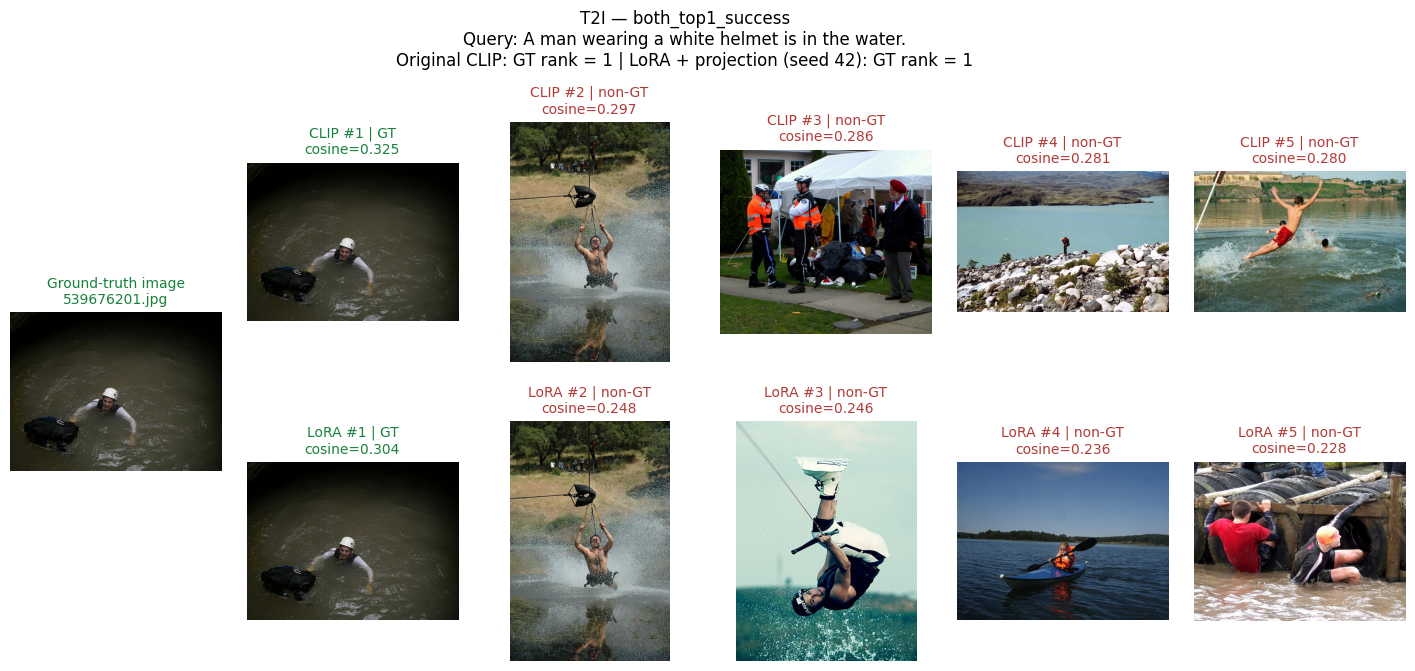


T2I / lora_top1_improvement: 候选=673，选中query=1008


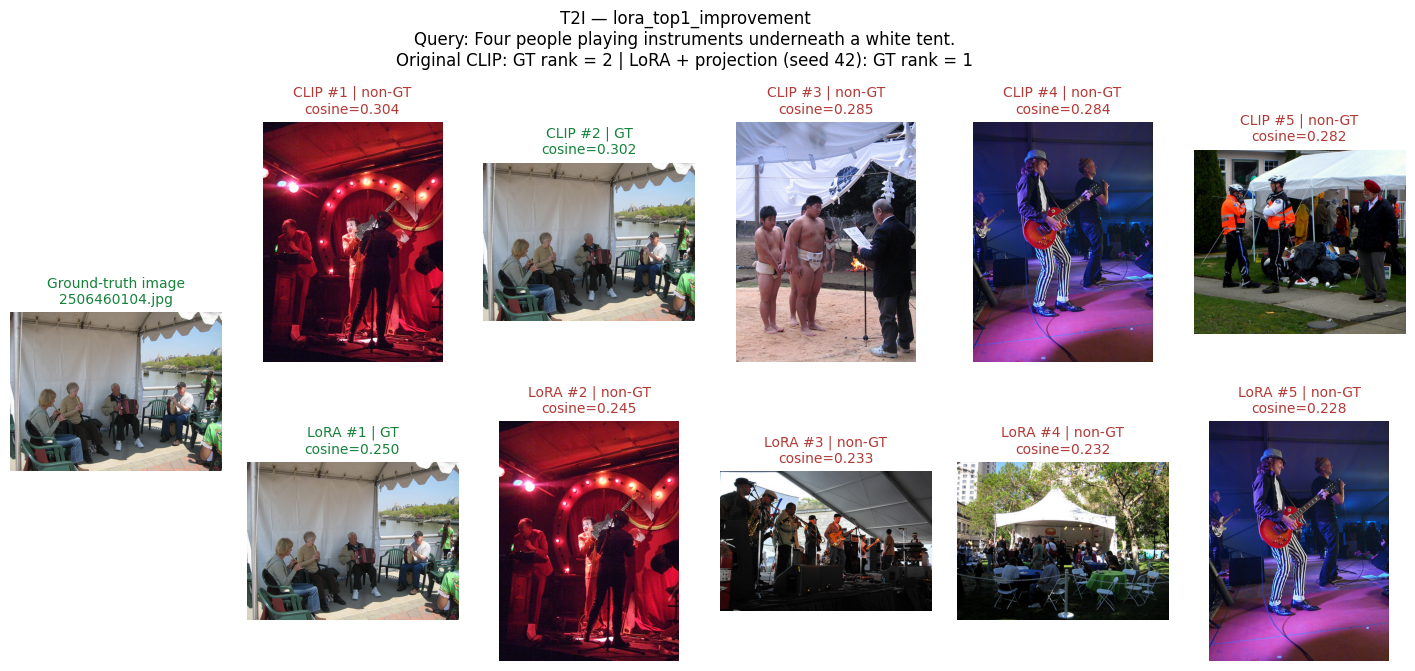


T2I / lora_top5_failure: 候选=480，选中query=88


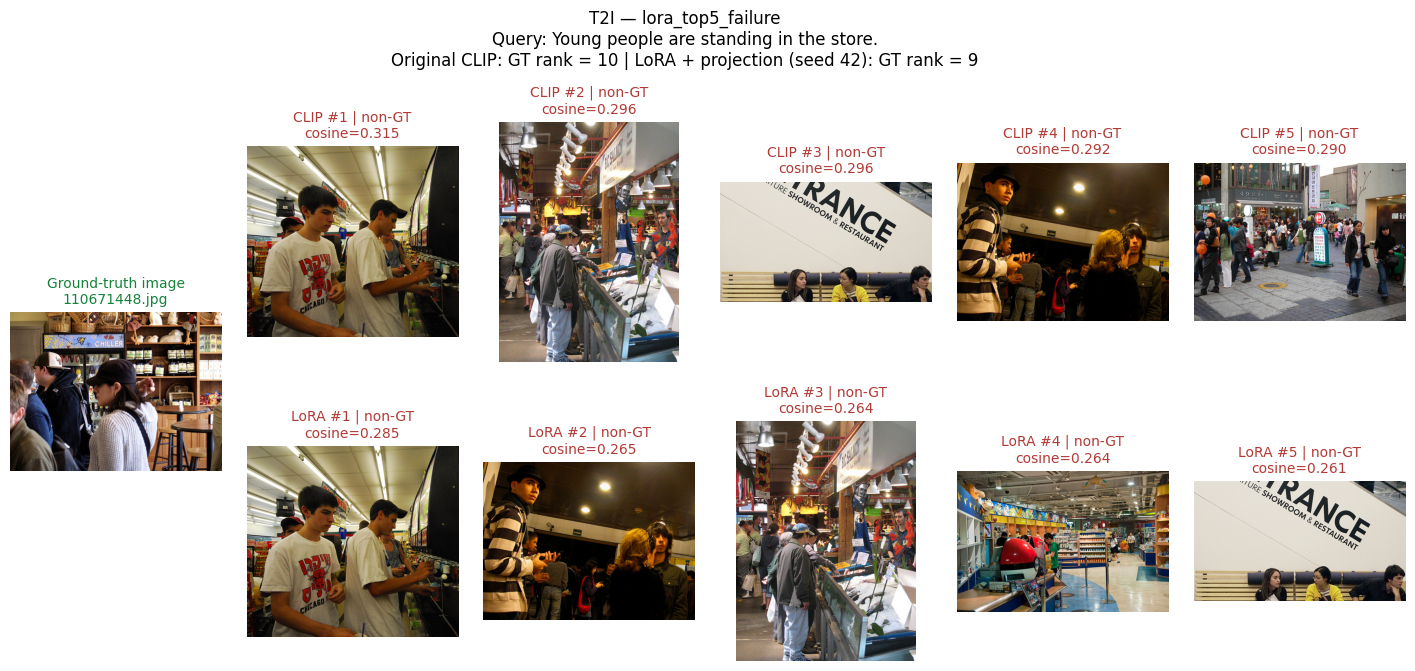


I2T / both_top1_success: 候选=750，选中query=646


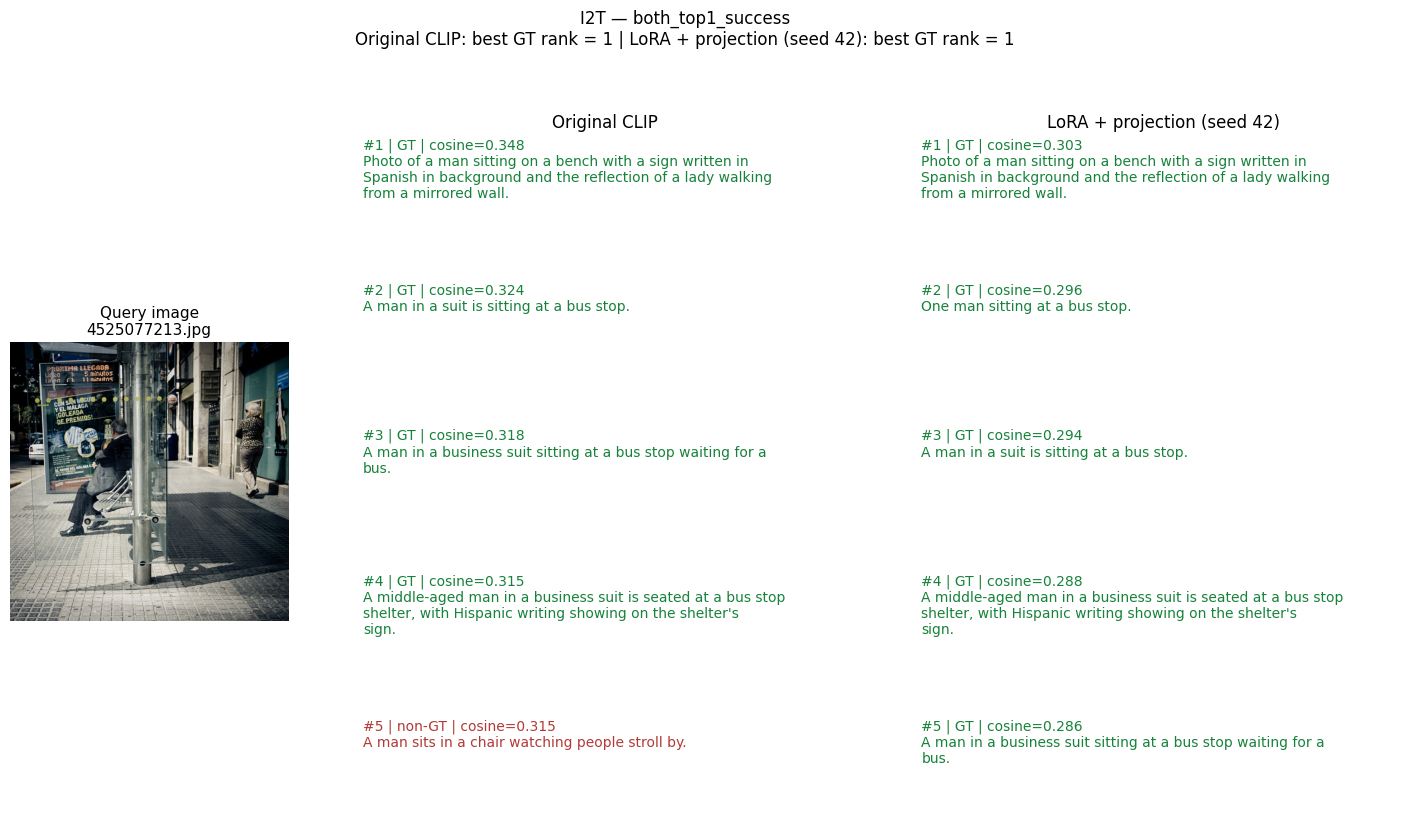


I2T / lora_top1_improvement: 候选=89，选中query=357


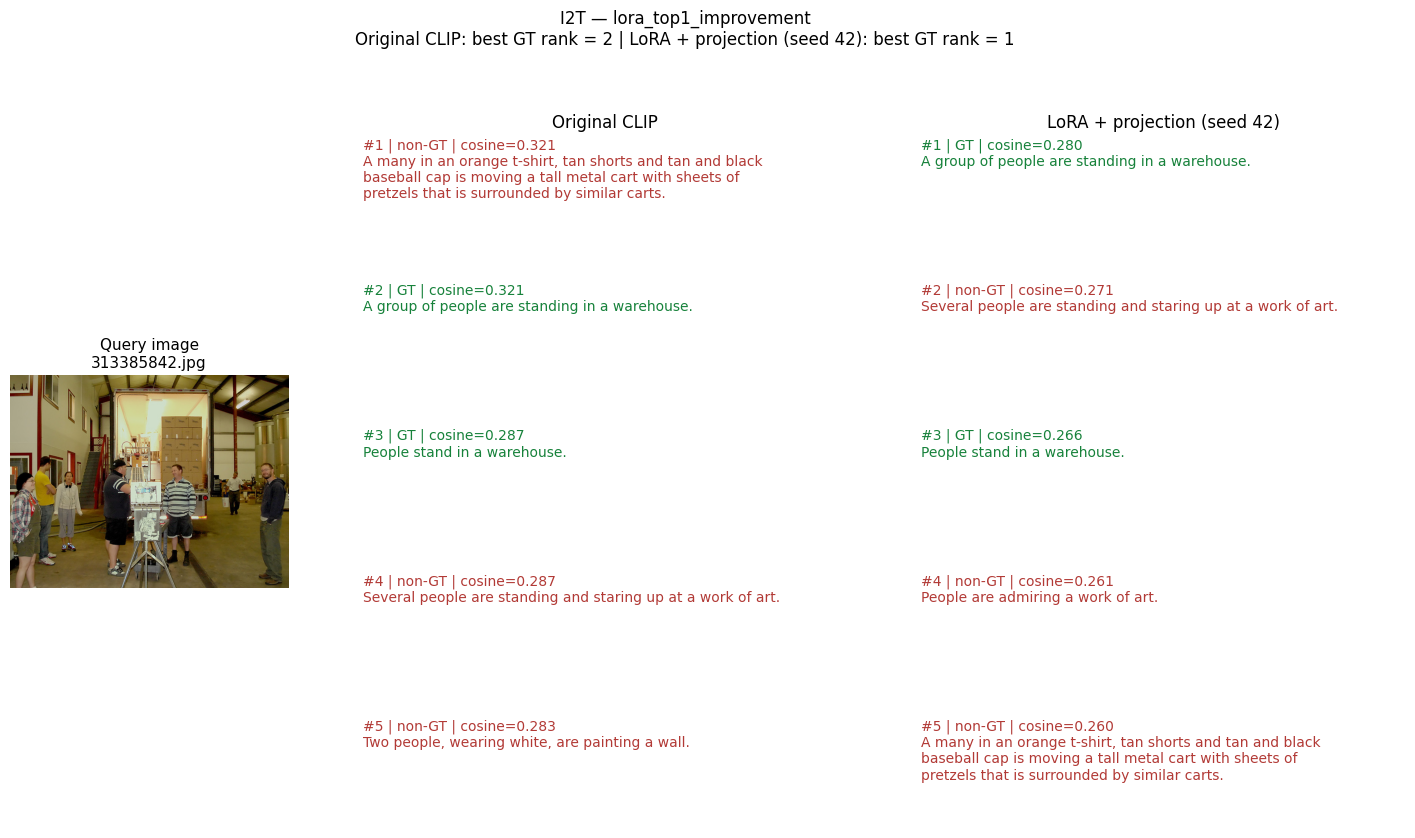


I2T / lora_top5_failure: 候选=25，选中query=446


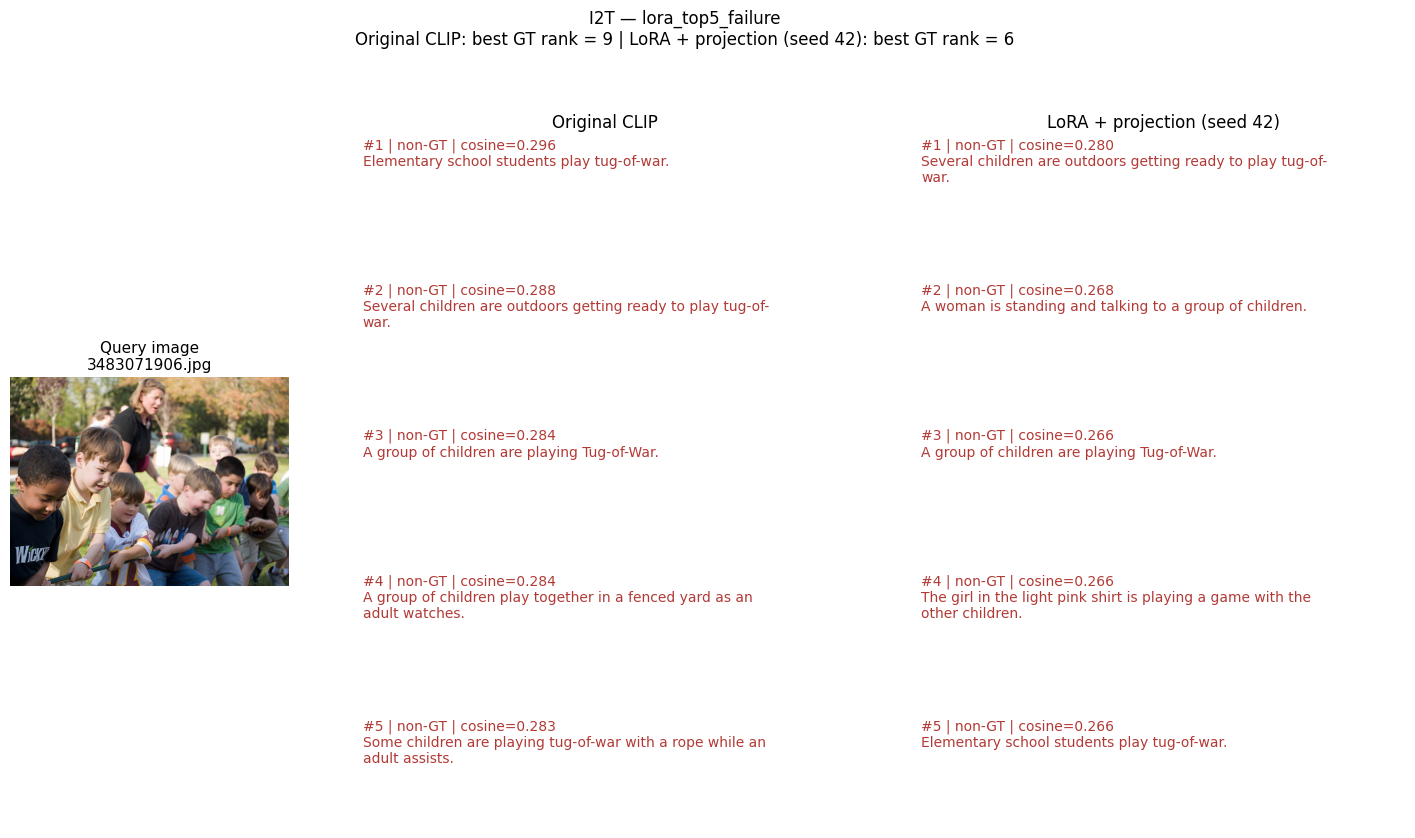


第13步检索可视化完成：6张PNG及完整选样记录。
保存目录： /kaggle/working/clip_retrieval/results/retrieval_visualizations
绿色=对应标注；红色=非对应标注。


In [6]:
print("[可视化] 开始读取已保存的测试特征与排名", flush=True)

import json
import textwrap
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from IPython.display import display

TEST_OUT = ROOT / "results" / "final_test"
VIS_OUT = ROOT / "results" / "retrieval_visualizations"
VIS_OUT.mkdir(parents=True, exist_ok=True)

IMG_DIR = Path(
    "/kaggle/input/datasets/mengxiao0351/"
    "flickr30k-images-local/flickr30k-images"
)

assert (TEST_OUT / "completed.json").is_file()

with open(TEST_OUT / "test_metadata.json", encoding="utf-8") as f:
    visual_metadata = json.load(f)

filenames = visual_metadata["filenames"]
captions = visual_metadata["captions"]
caption_to_image = np.asarray(
    visual_metadata["caption_to_image"], dtype=np.int64
)

image_features = torch.load(
    TEST_OUT / "test_image_features_fp32.pt",
    map_location="cpu",
    weights_only=True,
)

labels = {
    "A_baseline": "Original CLIP",
    "C_seed42": "LoRA + projection (seed 42)",
}
scores = {}
saved_ranks = {}

with torch.no_grad():
    for model_name in labels:
        text_features = torch.load(
            TEST_OUT / f"{model_name}_text_features_fp32.pt",
            map_location="cpu",
            weights_only=True,
        )
        assert image_features.shape == (1000, 512)
        assert text_features.shape == (5000, 512)

        scores[model_name] = (
            image_features.to(DEVICE)
            @ text_features.to(DEVICE).T
        ).cpu().numpy()

        with np.load(TEST_OUT / f"{model_name}_ranks.npz") as ranks:
            saved_ranks[model_name] = {
                direction: ranks[direction].copy()
                for direction in ("I2T", "T2I")
            }
        del text_features

GREEN = "#17823b"
RED = "#b23a36"


def read_picture(image_index):
    with Image.open(IMG_DIR / filenames[image_index]) as image:
        return image.convert("RGB")


def ranking_for_query(direction, query_index, model_name):
    matrix = scores[model_name]

    if direction == "T2I":
        order = np.argsort(-matrix[:, query_index], kind="stable")
        correct_image = int(caption_to_image[query_index])
        rank = int(np.flatnonzero(order == correct_image)[0]) + 1
    else:
        order = np.argsort(-matrix[query_index], kind="stable")
        rank = int(
            np.flatnonzero(
                caption_to_image[order] == query_index
            )[0]
        ) + 1

    # 确认用于绘图的排序与正式评估保存的排名一致
    assert rank == int(
        saved_ranks[model_name][direction][query_index]
    ), f"{direction}/{model_name} 的绘图排名与正式结果不一致"

    return order[:5], rank


def draw_t2i(query_index, case_name):
    correct_image = int(caption_to_image[query_index])
    fig = plt.figure(figsize=(18, 7))
    grid = fig.add_gridspec(2, 6, wspace=0.12, hspace=0.25)

    ground_truth_ax = fig.add_subplot(grid[:, 0])
    ground_truth_ax.imshow(read_picture(correct_image))
    ground_truth_ax.axis("off")
    ground_truth_ax.set_title(
        "Ground-truth image\n" + filenames[correct_image],
        fontsize=10,
        color=GREEN,
    )

    record = {
        "direction": "T2I",
        "case": case_name,
        "query_index": int(query_index),
        "query_caption": captions[query_index],
        "ground_truth_filename": filenames[correct_image],
        "models": {},
    }

    rank_labels = []

    for row, model_name in enumerate(labels):
        top5, correct_rank = ranking_for_query(
            "T2I", query_index, model_name
        )
        rank_labels.append(
            f"{labels[model_name]}: GT rank = {correct_rank}"
        )

        retrieved = []
        for column, image_index in enumerate(top5, start=1):
            image_index = int(image_index)
            hit = image_index == correct_image
            similarity = float(
                scores[model_name][image_index, query_index]
            )

            ax = fig.add_subplot(grid[row, column])
            ax.imshow(read_picture(image_index))
            ax.axis("off")
            ax.set_title(
                f"{'CLIP' if row == 0 else 'LoRA'} "
                f"#{column} | {'GT' if hit else 'non-GT'}\n"
                f"cosine={similarity:.3f}",
                color=GREEN if hit else RED,
                fontsize=10,
            )

            retrieved.append({
                "rank": column,
                "filename": filenames[image_index],
                "is_ground_truth": bool(hit),
                "similarity": similarity,
            })

        record["models"][model_name] = {
            "ground_truth_rank": correct_rank,
            "top5": retrieved,
        }

    fig.suptitle(
        f"T2I — {case_name}\n"
        + textwrap.fill("Query: " + captions[query_index], width=125)
        + "\n"
        + " | ".join(rank_labels),
        fontsize=12,
        y=1.04,
    )

    path = VIS_OUT / f"T2I_{case_name}.png"
    fig.savefig(path, dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)

    record["figure"] = path.name
    return record


def draw_i2t(query_index, case_name):
    fig = plt.figure(figsize=(18, 9))
    grid = fig.add_gridspec(
        5, 3, width_ratios=[1.15, 2, 2],
        wspace=0.18, hspace=0.3,
    )

    image_ax = fig.add_subplot(grid[:, 0])
    image_ax.imshow(read_picture(query_index))
    image_ax.axis("off")
    image_ax.set_title(
        "Query image\n" + filenames[query_index], fontsize=11
    )

    correct_captions = [
        captions[i]
        for i in np.flatnonzero(caption_to_image == query_index)
    ]
    record = {
        "direction": "I2T",
        "case": case_name,
        "query_index": int(query_index),
        "query_filename": filenames[query_index],
        "ground_truth_captions": correct_captions,
        "models": {},
    }

    rank_labels = []

    for column, model_name in enumerate(labels, start=1):
        top5, correct_rank = ranking_for_query(
            "I2T", query_index, model_name
        )
        rank_labels.append(
            f"{labels[model_name]}: best GT rank = {correct_rank}"
        )

        retrieved = []
        for row, caption_index in enumerate(top5):
            caption_index = int(caption_index)
            hit = int(caption_to_image[caption_index]) == query_index
            similarity = float(
                scores[model_name][query_index, caption_index]
            )

            ax = fig.add_subplot(grid[row, column])
            ax.axis("off")

            heading = (
                f"#{row + 1} | {'GT' if hit else 'non-GT'} "
                f"| cosine={similarity:.3f}"
            )
            ax.text(
                0, 0.98,
                heading + "\n" + textwrap.fill(
                    captions[caption_index], width=60
                ),
                va="top",
                fontsize=10,
                color=GREEN if hit else RED,
                transform=ax.transAxes,
            )
            if row == 0:
                ax.set_title(labels[model_name], fontsize=12)

            retrieved.append({
                "rank": row + 1,
                "caption_index": caption_index,
                "caption": captions[caption_index],
                "is_ground_truth": bool(hit),
                "similarity": similarity,
            })

        record["models"][model_name] = {
            "best_ground_truth_rank": correct_rank,
            "top5": retrieved,
        }

    fig.suptitle(
        f"I2T — {case_name}\n" + " | ".join(rank_labels),
        fontsize=12,
        y=1.02,
    )

    path = VIS_OUT / f"I2T_{case_name}.png"
    fig.savefig(path, dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)

    record["figure"] = path.name
    return record


# 固定规则与随机种子；不根据图片是否“好看”挑选
rng = np.random.default_rng(2026)
case_records = []

for direction in ("T2I", "I2T"):
    baseline = saved_ranks["A_baseline"][direction]
    lora = saved_ranks["C_seed42"][direction]

    categories = {
        "both_top1_success": (baseline == 1) & (lora == 1),
        "lora_top1_improvement": (baseline > 1) & (lora == 1),
        "lora_top5_failure": lora > 5,
    }

    for case_name, condition in categories.items():
        candidates = np.flatnonzero(condition)
        assert len(candidates) > 0, (
            f"{direction}/{case_name} 无可选样例"
        )

        query_index = int(rng.choice(candidates))
        print(
            f"\n{direction} / {case_name}: "
            f"候选={len(candidates)}，选中query={query_index}",
            flush=True,
        )

        if direction == "T2I":
            record = draw_t2i(query_index, case_name)
        else:
            record = draw_i2t(query_index, case_name)

        record["candidate_count"] = int(len(candidates))
        case_records.append(record)

with open(
    VIS_OUT / "case_selection_and_retrievals.json",
    "w", encoding="utf-8",
) as f:
    json.dump(
        {"selection_seed": 2026, "cases": case_records},
        f, ensure_ascii=False, indent=2,
    )

print("\n第13步检索可视化完成：6张PNG及完整选样记录。")
print("保存目录：", VIS_OUT)
print("绿色=对应标注；红色=非对应标注。")

## 20 Ground-truth captions for failure cases

Captured source and output from the original experiment.

In [7]:
import json

with open(
    VIS_OUT / "case_selection_and_retrievals.json",
    encoding="utf-8",
) as f:
    selected = json.load(f)

with open(TEST_OUT / "test_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

for case in selected["cases"]:
    if case["case"] != "lora_top5_failure":
        continue

    direction = case["direction"]
    query = case["query_index"]
    image_index = (
        metadata["caption_to_image"][query]
        if direction == "T2I" else query
    )

    print(f"\n===== {direction} 失败案例 =====")
    print("正确图片：", metadata["filenames"][image_index])
    if direction == "T2I":
        print("查询文本：", metadata["captions"][query])

    print("该图片的五条正确标注：")
    correct = [
        caption
        for caption, owner in zip(
            metadata["captions"],
            metadata["caption_to_image"],
        )
        if owner == image_index
    ]
    for number, caption in enumerate(correct, 1):
        print(f"{number}. {caption}")


===== T2I 失败案例 =====
正确图片： 110671448.jpg
查询文本： Young people are standing in the store.
该图片的五条正确标注：
1. A woman standing with 3 other people in a store with two tables, some shelves with coffee and tea for sale, and a refrigerated drink case.
2. A woman in a gray sweater and black baseball cap is standing in line at a shop.
3. A woman in a hat waits to be served at a store.
4. Young people are standing in the store.
5. A woman in a cap at a coffee shop.

===== I2T 失败案例 =====
正确图片： 3483071906.jpg
该图片的五条正确标注：
1. A group of kids with an adult in the background coaching them while they are pulling on a green rope.
2. Several young boys are pulling a rope in a park.
3. Little kids are playing a game of tug-of-war.
4. Children fight to win a tug-of-war battle.
5. Children are playing tug-of-war.


## 21 Parameter and MAC/FLOP accounting

Captured source and output from the original experiment.

In [8]:
print("[复杂度] 开始统计参数量与主要算子MACs", flush=True)

import gc
import json
from collections import defaultdict
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from IPython.display import display

COMPLEXITY_OUT = ROOT / "results" / "complexity"
COMPLEXITY_OUT.mkdir(parents=True, exist_ok=True)

with open(TEST_OUT / "test_metadata.json", encoding="utf-8") as f:
    profile_metadata = json.load(f)

# 使用真实图片及其对应的真实caption；仅用于计算量统计
profile_filename = profile_metadata["filenames"][0]
profile_caption = next(
    caption
    for caption, owner in zip(
        profile_metadata["captions"],
        profile_metadata["caption_to_image"],
    )
    if owner == 0
)

with Image.open(IMG_DIR / profile_filename) as image:
    profile_inputs = processor(
        images=image.convert("RGB"),
        text=[profile_caption],
        padding="max_length",
        truncation=True,
        max_length=77,
        return_tensors="pt",
    )

pixels = profile_inputs["pixel_values"].to(DEVICE)
tokens = {
    key: profile_inputs[key].to(DEVICE)
    for key in ("input_ids", "attention_mask")
}

assert pixels.shape == (1, 3, 224, 224)
assert tokens["input_ids"].shape == (1, 77)

print("图片：", profile_filename)
print("Caption：", profile_caption)
print("图片输入：", tuple(pixels.shape))
print("文本输入：", tuple(tokens["input_ids"].shape), flush=True)


def count_encoder_macs(model):
    counter = defaultdict(int)
    handles = []

    def linear_hook(module, args, output):
        # 每个输出向量需要 in_features × out_features 次MAC
        vectors = output.numel() // module.out_features
        counter["linear"] += (
            vectors * module.in_features * module.out_features
        )

    def conv_hook(module, args, output):
        kernel_h, kernel_w = module.kernel_size
        products_per_output = (
            module.in_channels // module.groups
        ) * kernel_h * kernel_w
        counter["conv2d"] += output.numel() * products_per_output

    def lora_hook(module, args, output):
        if not module.enabled:
            return
        x = args[0]
        vectors = x.numel() // module.base.in_features
        counter["lora"] += vectors * (
            module.base.in_features * module.r
            + module.r * module.base.out_features
        )
        counter["lora_calls"] += 1

    def attention_hook(module, args, kwargs, output):
        hidden = kwargs.get("hidden_states")
        if hidden is None:
            hidden = args[0]

        batch, length, width = hidden.shape

        # QK^T 与 attention_weights @ V
        # 使用完整稠密矩阵口径，包括被mask的位置
        counter["attention_matmul"] += (
            2 * batch * length * length * width
        )
        counter["attention_calls"] += 1

    for name, module in model.named_modules():
        if isinstance(module, nn.Linear):
            handles.append(
                module.register_forward_hook(linear_hook)
            )
        if isinstance(module, nn.Conv2d):
            handles.append(
                module.register_forward_hook(conv_hook)
            )
        if isinstance(module, ManualLoRALinear):
            handles.append(
                module.register_forward_hook(lora_hook)
            )
        if name.endswith(".self_attn"):
            handles.append(
                module.register_forward_hook(
                    attention_hook, with_kwargs=True
                )
            )

    try:
        model.float().eval()

        with torch.no_grad():
            counter.clear()
            pooled = model.vision_model(
                pixel_values=pixels
            ).pooler_output
            image_feature = F.normalize(
                model.visual_projection(pooled), dim=-1
            )
            image_counts = dict(counter)

            counter.clear()
            pooled = model.text_model(**tokens).pooler_output
            text_feature = F.normalize(
                model.text_projection(pooled), dim=-1
            )
            text_counts = dict(counter)

        assert torch.isfinite(image_feature).all()
        assert torch.isfinite(text_feature).all()
        assert image_counts["attention_calls"] == 12
        assert text_counts["attention_calls"] == 12
        assert image_counts.get("lora_calls", 0) == 0

        categories = ("linear", "conv2d", "attention_matmul", "lora")

        image_macs = sum(image_counts.get(k, 0) for k in categories)
        text_macs = sum(text_counts.get(k, 0) for k in categories)

        return image_macs, text_macs, image_counts, text_counts

    finally:
        for handle in handles:
            handle.remove()


rows = []
details = {}

for group, label in (
    ("A", "A: Original CLIP"),
    ("B", "B: Projection-only"),
    ("C", "C: LoRA + projection"),
):
    print(f"\n正在统计 {label}", flush=True)

    model = load_saved_retrieval_model(
        group, seed=42
    ).to(DEVICE).float().eval()

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    image_macs, text_macs, image_detail, text_detail = (
        count_encoder_macs(model)
    )
    pair_macs = image_macs + text_macs

    if group == "C":
        assert text_detail["lora_calls"] == 24
    else:
        assert text_detail.get("lora_calls", 0) == 0

    row = {
        "Group": group,
        "Model": label,
        "TotalParams": total_params,
        "TrainableParams": trainable_params,
        "TrainablePercent": 100 * trainable_params / total_params,
        "Image_GMACs": image_macs / 1e9,
        "Text77_GMACs": text_macs / 1e9,
        "Pair_GMACs": pair_macs / 1e9,
        "Image_GFLOPs": 2 * image_macs / 1e9,
        "Text77_GFLOPs": 2 * text_macs / 1e9,
        "Pair_GFLOPs": 2 * pair_macs / 1e9,
    }
    rows.append(row)

    details[group] = {
        "image_macs": image_macs,
        "text_macs": text_macs,
        "image_breakdown": image_detail,
        "text_breakdown": text_detail,
    }

    print(
        f"总参数={total_params:,}，"
        f"原训练策略可训练参数={trainable_params:,}"
    )
    print(
        f"图片={image_macs / 1e9:.6f} GMACs，"
        f"文本={text_macs / 1e9:.6f} GMACs",
        flush=True,
    )

    del model
    gc.collect()
    torch.cuda.empty_cache()


# 核对计数是否完整、一致
assert rows[0]["TotalParams"] == 151277313
assert rows[1]["TrainableParams"] == 262144
assert rows[2]["TrainableParams"] == 458752

assert details["A"]["image_macs"] == details["B"]["image_macs"]
assert details["A"]["image_macs"] == details["C"]["image_macs"]
assert details["A"]["text_macs"] == details["B"]["text_macs"]

# 24个Q/V LoRA分支，总共196608个LoRA参数，每个token使用一次
expected_extra_macs = 77 * 196608
actual_extra_macs = (
    details["C"]["text_macs"] - details["A"]["text_macs"]
)
assert actual_extra_macs == expected_extra_macs

table = pd.DataFrame(rows)
table.to_csv(
    COMPLEXITY_OUT / "params_and_compute.csv", index=False
)

report = {
    "input": {
        "image": [1, 3, 224, 224],
        "text": [1, 77],
        "real_image_filename": profile_filename,
        "real_caption": profile_caption,
    },
    "convention": {
        "flops_per_mac": 2,
        "attention": "dense full-length QK^T and attention @ V",
        "lora": "unmerged; both low-rank linear operations included",
        "included": [
            "Conv2d", "Linear", "attention matrix products",
            "manual LoRA matrix products",
        ],
        "excluded": [
            "bias and residual additions", "normalization",
            "activation", "softmax", "embedding lookup",
            "LoRA scaling", "gallery scoring and ranking",
        ],
        "scope": "theoretical dominant-operator compute; not hardware measurement",
    },
    "results": rows,
    "breakdown": details,
}

with open(
    COMPLEXITY_OUT / "compute_counting_details.json",
    "w", encoding="utf-8",
) as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("\n===== 参数量与理论计算量 =====")
display(table.round(6))

print(
    "\nLoRA新增计算量："
    f"{actual_extra_macs:,} MACs / 77-token文本"
)
print("计数一致性检查通过。")
print("第14步A完成，结果目录：", COMPLEXITY_OUT)
print("尚未测量推理速度；以上数值不是耗时或FPS。")

[复杂度] 开始统计参数量与主要算子MACs
图片： 1007129816.jpg
Caption： The man with pierced ears is wearing glasses and an orange hat.
图片输入： (1, 3, 224, 224)
文本输入： (1, 77)

正在统计 A: Original CLIP


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

总参数=151,277,313，原训练策略可训练参数=0
图片=4.408812 GMACs，文本=2.979770 GMACs

正在统计 B: Projection-only


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

总参数=151,277,313，原训练策略可训练参数=262,144
图片=4.408812 GMACs，文本=2.979770 GMACs

正在统计 C: LoRA + projection


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

总参数=151,473,921，原训练策略可训练参数=458,752
图片=4.408812 GMACs，文本=2.994909 GMACs

===== 参数量与理论计算量 =====


,Group,Model,TotalParams,TrainableParams,TrainablePercent,Image_GMACs,Text77_GMACs,Pair_GMACs,Image_GFLOPs,Text77_GFLOPs,Pair_GFLOPs
0,A,A: Original CLIP,151277313,0,0.000000,4.408812,2.979770,7.388582,8.817623,5.959541,14.777164
1,B,B: Projection-only,151277313,262144,0.173287,4.408812,2.979770,7.388582,8.817623,5.959541,14.777164
2,C,C: LoRA + projection,151473921,458752,0.302859,4.408812,2.994909,7.403721,8.817623,5.989818,14.807441



LoRA新增计算量：15,138,816 MACs / 77-token文本
计数一致性检查通过。
第14步A完成，结果目录： /kaggle/working/clip_retrieval/results/complexity
尚未测量推理速度；以上数值不是耗时或FPS。


## 22 Single-GPU latency and throughput

Captured source and output from the original experiment.

In [9]:
print("[测速] 开始准备真实输入与计时函数", flush=True)

import gc
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

DEVICE = torch.device("cuda:0")
torch.cuda.set_device(DEVICE)
assert torch.cuda.is_available()

TEST_OUT = ROOT / "results" / "final_test"
SPEED_OUT = ROOT / "results" / "complexity"
SPEED_OUT.mkdir(parents=True, exist_ok=True)

with open(TEST_OUT / "test_metadata.json", encoding="utf-8") as f:
    speed_metadata = json.load(f)

# ------------------------------------------------------------
# 1. 相同的32张真实图片及每图一条真实caption
#    读图、预处理、CPU→GPU搬运全部在计时之外
# ------------------------------------------------------------
speed_filenames = speed_metadata["filenames"][:32]
first_caption = {}

for caption, owner in zip(
    speed_metadata["captions"],
    speed_metadata["caption_to_image"],
):
    first_caption.setdefault(owner, caption)

speed_captions = [first_caption[i] for i in range(32)]

pictures = []
for filename in speed_filenames:
    with Image.open(IMG_DIR / filename) as image:
        pictures.append(image.convert("RGB"))

prepared = processor(
    images=pictures,
    text=speed_captions,
    padding="max_length",
    truncation=True,
    max_length=77,
    return_tensors="pt",
)

image_batch = prepared["pixel_values"].to(DEVICE).float()
text_batch = {
    key: prepared[key].to(DEVICE)
    for key in ("input_ids", "attention_mask")
}

image_single = image_batch[:1]
text_single = {
    key: value[:1] for key, value in text_batch.items()
}

assert image_batch.shape == (32, 3, 224, 224)
assert text_batch["input_ids"].shape == (32, 77)

# 完整去重图片候选库，1000张
image_gallery_features = torch.load(
    TEST_OUT / "test_image_features_fp32.pt",
    map_location="cpu",
    weights_only=True,
).to(DEVICE).float()

assert image_gallery_features.shape == (1000, 512)
image_gallery_T = image_gallery_features.T.contiguous()

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("编码输入：相同32张真实图片、32条真实caption")
print("文本统一填充至77 tokens；精度FP32", flush=True)


# ------------------------------------------------------------
# 2. 编码函数：包括投影与L2归一化
# ------------------------------------------------------------
def encode_image(model, pixels):
    pooled = model.vision_model(
        pixel_values=pixels
    ).pooler_output
    return F.normalize(model.visual_projection(pooled), dim=-1)


def encode_text(model, tokens):
    pooled = model.text_model(**tokens).pooler_output
    return F.normalize(model.text_projection(pooled), dim=-1)


# ------------------------------------------------------------
# 3. 同步墙钟延迟：包含Python调用、GPU执行及完成同步
# ------------------------------------------------------------
@torch.inference_mode()
def measure_latency(fn, label, warmup=20, repeats=100):
    for _ in range(warmup):
        output = fn()
    torch.cuda.synchronize(DEVICE)

    samples_ms = []

    for _ in tqdm(range(repeats), desc=label):
        torch.cuda.synchronize(DEVICE)
        start = time.perf_counter()

        output = fn()
        torch.cuda.synchronize(DEVICE)

        samples_ms.append(
            (time.perf_counter() - start) * 1000
        )

    values = np.asarray(samples_ms)
    return {
        "mean_ms": float(values.mean()),
        "median_ms": float(np.median(values)),
        "p95_ms": float(np.percentile(values, 95)),
        "samples_ms": samples_ms,
    }


# ------------------------------------------------------------
# 4. 吞吐量：每轮连续执行10个batch，共5轮
#    每轮边界同步，避免每个batch都强制等待
# ------------------------------------------------------------
@torch.inference_mode()
def measure_throughput(
    fn, label, batch_size=32, warmup=10, rounds=5, steps=10
):
    for _ in range(warmup):
        output = fn()
    torch.cuda.synchronize(DEVICE)

    durations = []

    for _ in tqdm(range(rounds), desc=label):
        torch.cuda.synchronize(DEVICE)
        start = time.perf_counter()

        for _ in range(steps):
            output = fn()

        torch.cuda.synchronize(DEVICE)
        durations.append(time.perf_counter() - start)

    total_items = batch_size * rounds * steps

    return {
        "items_per_second": float(
            total_items / sum(durations)
        ),
        "mean_batch_ms": float(
            1000 * sum(durations) / (rounds * steps)
        ),
        "round_seconds": durations,
        "batch_size": batch_size,
        "rounds": rounds,
        "steps_per_round": steps,
    }


# 若之前保留的恢复模型仍在GPU，先移至CPU
if "restored_c_model" in globals():
    restored_c_model.cpu()

gc.collect()
torch.cuda.empty_cache()

speed_rows = []
raw_measurements = {}

# ------------------------------------------------------------
# 5. A/B/C采用相同输入、相同测量次数
# ------------------------------------------------------------
for group, feature_label in (
    ("A", "A_baseline"),
    ("B", "B_seed42"),
    ("C", "C_seed42"),
):
    print(f"\n===== 开始 {group} 组测速 =====", flush=True)

    current = load_saved_retrieval_model(
        group, seed=42
    ).to(DEVICE).float().eval()

    # 先检查实际输出
    with torch.inference_mode():
        check_image = encode_image(current, image_single)
        check_text = encode_text(current, text_single)

    assert check_image.shape == (1, 512)
    assert check_text.shape == (1, 512)
    assert torch.isfinite(check_image).all()
    assert torch.isfinite(check_text).all()
    del check_image, check_text

    image_latency = measure_latency(
        lambda: encode_image(current, image_single),
        f"{group} 图片编码 B=1",
    )
    text_latency = measure_latency(
        lambda: encode_text(current, text_single),
        f"{group} 文本编码 B=1",
    )

    image_throughput = measure_throughput(
        lambda: encode_image(current, image_batch),
        f"{group} 图片吞吐 B=32",
    )
    text_throughput = measure_throughput(
        lambda: encode_text(current, text_batch),
        f"{group} 文本吞吐 B=32",
    )

    # 当前模型对应的5000条真实测试caption特征
    text_gallery_features = torch.load(
        TEST_OUT / f"{feature_label}_text_features_fp32.pt",
        map_location="cpu",
        weights_only=True,
    ).to(DEVICE).float()

    assert text_gallery_features.shape == (5000, 512)
    text_gallery_T = text_gallery_features.T.contiguous()

    # 轮换64条已编码查询；候选库始终完整
    t2i_queries = [
        text_gallery_features[i:i + 1] for i in range(64)
    ]
    i2t_queries = [
        image_gallery_features[i:i + 1] for i in range(64)
    ]
    positions = {"T2I": 0, "I2T": 0}

    def cached_t2i():
        index = positions["T2I"] % len(t2i_queries)
        positions["T2I"] += 1
        similarity = t2i_queries[index] @ image_gallery_T
        return torch.topk(
            similarity, k=5, dim=-1, largest=True, sorted=True
        )

    def cached_i2t():
        index = positions["I2T"] % len(i2t_queries)
        positions["I2T"] += 1
        similarity = i2t_queries[index] @ text_gallery_T
        return torch.topk(
            similarity, k=5, dim=-1, largest=True, sorted=True
        )

    t2i_latency = measure_latency(
        cached_t2i,
        f"{group} 缓存T2I Top5 / 1000图片",
        repeats=200,
    )
    i2t_latency = measure_latency(
        cached_i2t,
        f"{group} 缓存I2T Top5 / 5000文本",
        repeats=200,
    )

    row = {
        "Group": group,
        "Image_B1_mean_ms": image_latency["mean_ms"],
        "Image_B1_p95_ms": image_latency["p95_ms"],
        "Text77_B1_mean_ms": text_latency["mean_ms"],
        "Text77_B1_p95_ms": text_latency["p95_ms"],
        "Image_B32_images_s": image_throughput["items_per_second"],
        "Text77_B32_texts_s": text_throughput["items_per_second"],
        "T2I_cached_Top5_mean_ms": t2i_latency["mean_ms"],
        "I2T_cached_Top5_mean_ms": i2t_latency["mean_ms"],
    }
    speed_rows.append(row)

    raw_measurements[group] = {
        "image_b1_latency": image_latency,
        "text77_b1_latency": text_latency,
        "image_b32_throughput": image_throughput,
        "text77_b32_throughput": text_throughput,
        "t2i_cached_top5_latency": t2i_latency,
        "i2t_cached_top5_latency": i2t_latency,
    }

    print(
        f"{group} 图片编码：{row['Image_B1_mean_ms']:.3f} ms/张；"
        f"文本编码：{row['Text77_B1_mean_ms']:.3f} ms/条",
        flush=True,
    )
    print(
        f"{group} Batch32吞吐："
        f"{row['Image_B32_images_s']:.2f} images/s，"
        f"{row['Text77_B32_texts_s']:.2f} texts/s",
        flush=True,
    )

    del current, text_gallery_features, text_gallery_T
    del t2i_queries, i2t_queries
    gc.collect()
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 6. 保存表格、原始计时样本与完整测量口径
# ------------------------------------------------------------
speed_table = pd.DataFrame(speed_rows)
speed_table.to_csv(
    SPEED_OUT / "inference_speed.csv", index=False
)

speed_report = {
    "environment": {
        "gpu": torch.cuda.get_device_name(DEVICE),
        "device": str(DEVICE),
        "torch": str(torch.__version__),
        "transformers": transformers.__version__,
        "cuda": torch.version.cuda,
        "precision": "float32",
        "autocast": False,
        "compiled": False,
        "lora": "unmerged",
        "checkpoint_seed": 42,
    },
    "protocol": {
        "encoder_image_shape": [1, 3, 224, 224],
        "encoder_text_shape": [1, 77],
        "latency": "synchronized wall-clock; mean, median and p95",
        "encoder_latency_warmup": 20,
        "encoder_latency_repeats": 100,
        "throughput_batch_size": 32,
        "throughput_warmup": 10,
        "throughput_rounds": 5,
        "throughput_steps_per_round": 10,
        "retrieval_latency_warmup": 20,
        "retrieval_latency_repeats": 200,
        "retrieval_topk": 5,
        "t2i_gallery_images": 1000,
        "i2t_gallery_captions": 5000,
        "retrieval_query_bank_size": 64,
        "encoder_scope": "encoder + projection + L2 normalization",
        "retrieval_scope": "cached query/gallery dot product + sorted Top5",
        "outside_timing": [
            "model loading",
            "file reading",
            "image preprocessing",
            "text tokenization",
            "CPU-GPU input transfer",
            "gallery feature extraction",
            "GPU-CPU result transfer",
            "visualization",
        ],
        "input_image_filenames": speed_filenames,
        "input_captions": speed_captions,
    },
    "summary": speed_rows,
    "raw_measurements": raw_measurements,
}

with open(
    SPEED_OUT / "inference_speed_details.json",
    "w", encoding="utf-8",
) as f:
    json.dump(speed_report, f, ensure_ascii=False, indent=2)

print("\n===== 单GPU FP32测速结果 =====")
display(speed_table.round(4))

print("\n第14步B完成。")
print("结果目录：", SPEED_OUT)
print("图片吞吐量单位为images/s，文本吞吐量单位为texts/s。")
print("结果覆盖GPU驻留输入下的编码与缓存匹配，不含预处理和传输。")

[测速] 开始准备真实输入与计时函数
GPU: Tesla T4
编码输入：相同32张真实图片、32条真实caption
文本统一填充至77 tokens；精度FP32

===== 开始 A 组测速 =====


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

A 图片编码 B=1:   0%|          | 0/100 [00:00<?, ?it/s]

A 文本编码 B=1:   0%|          | 0/100 [00:00<?, ?it/s]

A 图片吞吐 B=32:   0%|          | 0/5 [00:00<?, ?it/s]

A 文本吞吐 B=32:   0%|          | 0/5 [00:00<?, ?it/s]

... (17 outputs left out)

C 缓存I2T Top5 / 5000文本:   0%|          | 0/200 [00:00<?, ?it/s]

C 图片编码：6.546 ms/张；文本编码：9.727 ms/条
C Batch32吞吐：360.80 images/s，478.20 texts/s

===== 单GPU FP32测速结果 =====


,Group,Image_B1_mean_ms,Image_B1_p95_ms,Text77_B1_mean_ms,Text77_B1_p95_ms,Image_B32_images_s,Text77_B32_texts_s,T2I_cached_Top5_mean_ms,I2T_cached_Top5_mean_ms
0,A,6.4715,7.3945,7.7652,8.9708,362.4610,500.9789,0.0668,0.1058
1,B,6.8642,9.8065,7.5963,8.5995,346.2174,497.0435,0.0695,0.1103
2,C,6.5463,7.5971,9.7268,11.1669,360.7998,478.2041,0.0736,0.1064



第14步B完成。
结果目录： /kaggle/working/clip_retrieval/results/complexity
图片吞吐量单位为images/s，文本吞吐量单位为texts/s。
结果覆盖GPU驻留输入下的编码与缓存匹配，不含预处理和传输。


## 23 Paper figures and summary tables

Captured source and output from the original experiment.

[绘图] 开始读取已保存的日志和实验结果


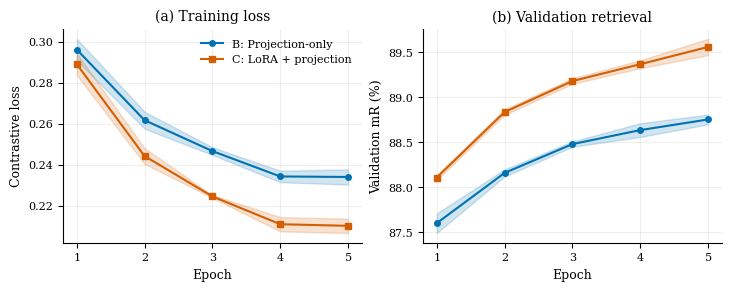

已保存：fig01_training_and_validation.png / .pdf


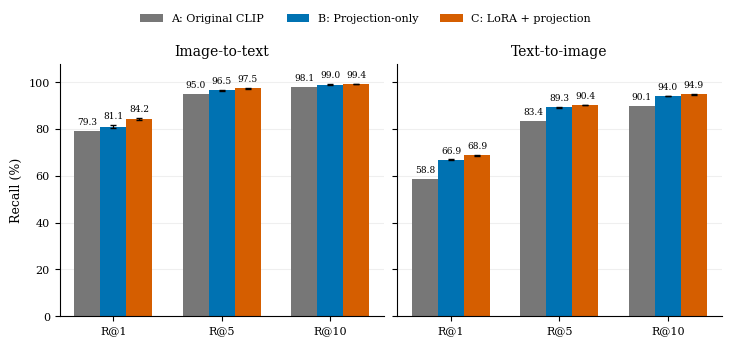

已保存：fig02_test_bidirectional_recall.png / .pdf


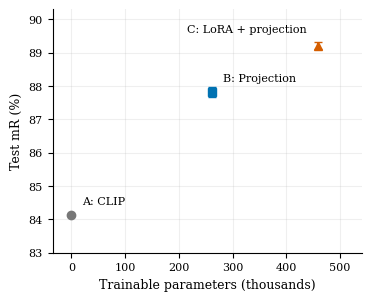

已保存：fig03_trainable_parameters_vs_test_mR.png / .pdf


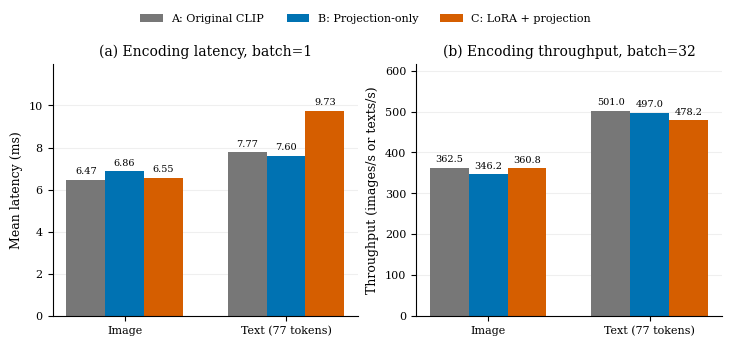

已保存：fig04_encoding_latency_and_throughput.png / .pdf

===== 论文主结果表 =====


,Model,I2T_R@1,I2T_R@5,I2T_R@10,I2T_MedianRank,T2I_R@1,T2I_R@5,T2I_R@10,T2I_MedianRank,mR
0,A: Original CLIP,79.30,95.00,98.10,1.00,58.84,83.44,90.08,1.00,84.13
1,B: Projection-only,81.10 ± 0.52,96.53 ± 0.15,99.03 ± 0.21,1.00 ± 0.00,66.91 ± 0.13,89.29 ± 0.14,94.04 ± 0.03,1.00 ± 0.00,87.82 ± 0.14
2,C: LoRA + projection,84.17 ± 0.46,97.53 ± 0.15,99.40 ± 0.10,1.00 ± 0.00,68.87 ± 0.27,90.40 ± 0.02,94.87 ± 0.10,1.00 ± 0.00,89.21 ± 0.11



===== 导出文件 =====
fig01_training_and_validation.png
fig01_training_and_validation.pdf
fig02_test_bidirectional_recall.png
fig02_test_bidirectional_recall.pdf
fig03_trainable_parameters_vs_test_mR.png
fig03_trainable_parameters_vs_test_mR.pdf
fig04_encoding_latency_and_throughput.png
fig04_encoding_latency_and_throughput.pdf

CSV：
training_curves_source.csv
test_summary_source.csv
paper_results_table.csv
paper_efficiency_table.csv
图注与统计口径：figure_notes.json

第15步图表生成完成。
保存目录： /kaggle/working/clip_retrieval/results/paper_figures
共4组图、8个PNG/PDF文件，另附汇总表和绘图数据。
未训练模型；未重新执行测试集评估。


In [10]:
print("[绘图] 开始读取已保存的日志和实验结果", flush=True)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

TEST_OUT = ROOT / "results" / "final_test"
COMPLEXITY_OUT = ROOT / "results" / "complexity"
FIG_OUT = ROOT / "results" / "paper_figures"
FIG_OUT.mkdir(parents=True, exist_ok=True)

SEEDS = (42, 43, 44)
GROUPS = ("A", "B", "C")
COLORS = {"A": "#777777", "B": "#0072B2", "C": "#D55E00"}
LABELS = {
    "A": "A: Original CLIP",
    "B": "B: Projection-only",
    "C": "C: LoRA + projection",
}

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white",
})

figure_notes = {}
generated_files = []


def save_figure(fig, name, note):
    for extension in ("png", "pdf"):
        path = FIG_OUT / f"{name}.{extension}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        assert path.is_file() and path.stat().st_size > 0
        generated_files.append(path.name)

    figure_notes[name] = note
    display(fig)
    plt.close(fig)
    print(f"已保存：{name}.png / .pdf", flush=True)


# ============================================================
# 1. 读取六份训练日志
# ============================================================
histories = {}
training_source = []

for group in ("B", "C"):
    for seed in SEEDS:
        folder = (
            f"B_projection_seed{seed}"
            if group == "B"
            else f"C_lora_r8_seed{seed}"
        )

        with open(
            ROOT / "results" / folder / "summary.json",
            encoding="utf-8",
        ) as f:
            summary = json.load(f)

        assert summary["seed"] == seed
        history = sorted(summary["history"], key=lambda x: x["epoch"])
        assert [x["epoch"] for x in history] == [1, 2, 3, 4, 5]

        histories[(group, seed)] = history

        for item in history:
            training_source.append({
                "Group": group,
                "Seed": seed,
                "Epoch": item["epoch"],
                "TrainLoss": item["train_loss"],
                "Validation_mR": item["val"]["mR"],
                "TrainSeconds": item["train_seconds"],
                "PeakAllocatedGiB": item["peak_allocated_gib"],
            })

pd.DataFrame(training_source).to_csv(
    FIG_OUT / "training_curves_source.csv", index=False
)


# ============================================================
# 2. 从最终测试原始结果计算均值与样本标准差
# ============================================================
with open(TEST_OUT / "completed.json", encoding="utf-8") as f:
    completed = json.load(f)

runs = completed["runs"]
assert len(runs) == 7

metric_names = [
    f"{direction}_{metric}"
    for direction in ("I2T", "T2I")
    for metric in ("R@1", "R@5", "R@10", "MedianRank")
] + ["mR"]


def read_metric(run, metric):
    if metric == "mR":
        return float(run["metrics"]["mR"])
    direction, name = metric.split("_", 1)
    return float(run["metrics"][direction][name])


statistics = {}
statistics_rows = []

for group in GROUPS:
    selected = [run for run in runs if run["group"] == group]

    if group == "A":
        assert len(selected) == 1
    else:
        assert len(selected) == 3
        assert {run["seed"] for run in selected} == set(SEEDS)

    statistics[group] = {}

    for metric in metric_names:
        values = np.array(
            [read_metric(run, metric) for run in selected],
            dtype=float,
        )
        mean = float(values.mean())
        std = float(values.std(ddof=1)) if len(values) > 1 else 0.0

        statistics[group][metric] = (mean, std)
        statistics_rows.append({
            "Group": group,
            "Metric": metric,
            "Mean": mean,
            "SampleStd": std if group != "A" else None,
            "Runs": len(values),
        })

pd.DataFrame(statistics_rows).to_csv(
    FIG_OUT / "test_summary_source.csv", index=False
)

# 与之前保存的汇总CSV核对
previous = pd.read_csv(TEST_OUT / "test_mean_std.csv")
for row in previous.to_dict("records"):
    mean, std = statistics[row["Group"]][row["Metric"]]
    assert np.isclose(mean, row["Mean"], atol=1e-9)
    assert np.isclose(std, row["SampleStd"], atol=1e-9)

params = pd.read_csv(
    COMPLEXITY_OUT / "params_and_compute.csv"
).set_index("Group")

speed = pd.read_csv(
    COMPLEXITY_OUT / "inference_speed.csv"
).set_index("Group")

assert set(params.index) == set(GROUPS)
assert set(speed.index) == set(GROUPS)


# ============================================================
# 图1：训练loss和验证mR，均值±样本标准差
# ============================================================
epochs = np.arange(1, 6)
fig, axes = plt.subplots(
    1, 2, figsize=(7.2, 2.8), constrained_layout=True
)

for group in ("B", "C"):
    losses = np.array([
        [item["train_loss"] for item in histories[(group, seed)]]
        for seed in SEEDS
    ])
    validation = np.array([
        [item["val"]["mR"] for item in histories[(group, seed)]]
        for seed in SEEDS
    ])

    for ax, values in zip(axes, (losses, validation)):
        mean = values.mean(axis=0)
        std = values.std(axis=0, ddof=1)

        ax.plot(
            epochs, mean,
            marker="o" if group == "B" else "s",
            markersize=4,
            color=COLORS[group],
            label=LABELS[group],
        )
        ax.fill_between(
            epochs, mean - std, mean + std,
            color=COLORS[group], alpha=0.18,
        )

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.2)

axes[0].set_title("(a) Training loss")
axes[0].set_ylabel("Contrastive loss")
axes[0].legend(frameon=False)

axes[1].set_title("(b) Validation retrieval")
axes[1].set_ylabel("Validation mR (%)")

save_figure(
    fig,
    "fig01_training_and_validation",
    "B/C curves show mean ± sample standard deviation across "
    "seeds 42, 43 and 44 at each epoch. No smoothing is applied. "
    "Training loss and validation mR use different y-axis scales.",
)


# ============================================================
# 图2：双向Recall，三组并列柱形图
# ============================================================
fig, axes = plt.subplots(
    1, 2, figsize=(7.2, 3.0), sharey=True,
    constrained_layout=True,
)
x = np.arange(3)
width = 0.24

for ax, direction in zip(axes, ("I2T", "T2I")):
    for offset, group in enumerate(GROUPS):
        values = [
            statistics[group][f"{direction}_R@{k}"][0]
            for k in (1, 5, 10)
        ]
        errors = [
            statistics[group][f"{direction}_R@{k}"][1]
            for k in (1, 5, 10)
        ]

        bars = ax.bar(
            x + (offset - 1) * width,
            values,
            width=width,
            color=COLORS[group],
            label=LABELS[group],
            yerr=errors if group != "A" else None,
            capsize=2,
            error_kw={"elinewidth": 0.9},
        )
        ax.bar_label(
            bars, labels=[f"{v:.1f}" for v in values],
            padding=3, fontsize=6.5,
        )

    ax.set_xticks(x, ["R@1", "R@5", "R@10"])
    ax.set_ylim(0, 108)
    ax.set_title(
        "Image-to-text" if direction == "I2T" else "Text-to-image"
    )
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Recall (%)")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, legend_labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.12),
    ncol=3, frameon=False,
)

save_figure(
    fig,
    "fig02_test_bidirectional_recall",
    "Test galleries contain 1000 images and 5000 captions. "
    "A is one deterministic zero-shot baseline; B/C bars show "
    "means across three seeds, with sample standard deviations. "
    "Error bars are not confidence intervals.",
)


# ============================================================
# 图3：可训练参数量与测试mR
# ============================================================
fig, ax = plt.subplots(
    figsize=(3.6, 2.9), constrained_layout=True
)

for group in GROUPS:
    trainable_k = float(params.loc[group, "TrainableParams"]) / 1000
    mean, std = statistics[group]["mR"]

    ax.errorbar(
        trainable_k, mean,
        yerr=std if group != "A" else None,
        fmt={"A": "o", "B": "s", "C": "^"}[group],
        color=COLORS[group],
        markersize=6,
        capsize=3,
    )
    ax.annotate(
        {"A": "A: CLIP", "B": "B: Projection", "C": "C: LoRA + projection"}[group],
        xy=(trainable_k, mean),
        xytext=(-8, 10) if group == "C" else (8, 8),
        textcoords="offset points",
        ha="right" if group == "C" else "left",
        fontsize=8,
    )

ax.set_xlabel("Trainable parameters (thousands)")
ax.set_ylabel("Test mR (%)")
ax.set_xlim(-35, 540)
ax.set_ylim(83, 90.3)
ax.grid(alpha=0.2)

save_figure(
    fig,
    "fig03_trainable_parameters_vs_test_mR",
    "Trainable parameters follow each training strategy. "
    "A has zero trainable parameters but retains the full pretrained model. "
    "B/C mR values are three-seed means with sample standard deviations. "
    "Points represent different strategies, not a rank sweep.",
)


# ============================================================
# 图4：FP32编码延迟和Batch32吞吐
# ============================================================
fig, axes = plt.subplots(
    1, 2, figsize=(7.2, 3.0), constrained_layout=True
)
x = np.arange(2)
width = 0.24

for offset, group in enumerate(GROUPS):
    latency_values = [
        float(speed.loc[group, "Image_B1_mean_ms"]),
        float(speed.loc[group, "Text77_B1_mean_ms"]),
    ]
    throughput_values = [
        float(speed.loc[group, "Image_B32_images_s"]),
        float(speed.loc[group, "Text77_B32_texts_s"]),
    ]

    for ax, values in zip(
        axes, (latency_values, throughput_values)
    ):
        bars = ax.bar(
            x + (offset - 1) * width,
            values, width=width,
            color=COLORS[group], label=LABELS[group],
        )
        ax.bar_label(
            bars,
            labels=[
                f"{v:.2f}" if ax is axes[0] else f"{v:.1f}"
                for v in values
            ],
            padding=3, fontsize=7,
        )

for ax in axes:
    ax.set_xticks(x, ["Image", "Text (77 tokens)"])
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_title("(a) Encoding latency, batch=1")
axes[0].set_ylabel("Mean latency (ms)")
axes[0].set_ylim(
    0, speed[["Image_B1_mean_ms", "Text77_B1_mean_ms"]]
    .to_numpy().max() * 1.23
)

axes[1].set_title("(b) Encoding throughput, batch=32")
axes[1].set_ylabel("Throughput (images/s or texts/s)")
axes[1].set_ylim(
    0, speed[["Image_B32_images_s", "Text77_B32_texts_s"]]
    .to_numpy().max() * 1.23
)

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, legend_labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.12),
    ncol=3, frameon=False,
)

save_figure(
    fig,
    "fig04_encoding_latency_and_throughput",
    "Single Tesla T4, FP32, seed42 checkpoints, unmerged LoRA. "
    "Latency bars show synchronized wall-clock means over 100 calls. "
    "Throughput uses five rounds of ten batch32 calls. "
    "Preprocessing, file I/O and CPU-GPU transfer are outside timing. "
    "These are timing measurements, not three-training-seed averages.",
)


# ============================================================
# 3. 输出论文结果表和效率表
# ============================================================
paper_rows = []

for group in GROUPS:
    row = {"Model": LABELS[group]}

    for metric in metric_names:
        mean, std = statistics[group][metric]
        row[metric] = (
            f"{mean:.2f}"
            if group == "A"
            else f"{mean:.2f} ± {std:.2f}"
        )

    paper_rows.append(row)

paper_results = pd.DataFrame(paper_rows)
paper_results.to_csv(
    FIG_OUT / "paper_results_table.csv",
    index=False, encoding="utf-8-sig",
)

efficiency = (
    params.reset_index()
    .merge(
        speed.reset_index(),
        on="Group",
        validate="one_to_one",
    )
)
efficiency.to_csv(
    FIG_OUT / "paper_efficiency_table.csv",
    index=False, encoding="utf-8-sig",
)

with open(
    FIG_OUT / "figure_notes.json", "w", encoding="utf-8"
) as f:
    json.dump(figure_notes, f, ensure_ascii=False, indent=2)

print("\n===== 论文主结果表 =====")
display(paper_results)

print("\n===== 导出文件 =====")
for filename in generated_files:
    print(filename)

print("\nCSV：")
print("training_curves_source.csv")
print("test_summary_source.csv")
print("paper_results_table.csv")
print("paper_efficiency_table.csv")
print("图注与统计口径：figure_notes.json")

print("\n第15步图表生成完成。")
print("保存目录：", FIG_OUT)
print("共4组图、8个PNG/PDF文件，另附汇总表和绘图数据。")
print("未训练模型；未重新执行测试集评估。")

## 24 Training history reconstructed from saved summaries

The following output displays historical saved summaries; it is not new training.

In [11]:
print("[归档] 从已保存文件恢复展示训练记录，不执行训练", flush=True)

import json
from pathlib import Path
import pandas as pd
from IPython.display import display, JSON

ROOT = Path("/kaggle/working/clip_retrieval")
ARCHIVE_OUT = ROOT / "results" / "submission_metadata"
ARCHIVE_OUT.mkdir(parents=True, exist_ok=True)

payload = {
    "provenance": (
        "Displayed from previously saved experiment summaries. "
        "These are historical training records, not newly executed training."
    ),
    "experiments": {},
}

with open(
    ROOT / "results/baseline_val.json", encoding="utf-8"
) as f:
    payload["baseline_validation"] = json.load(f)

rows = []

for seed in (42, 43, 44):
    for group, prefix in (
        ("B", "B_projection"),
        ("C", "C_lora_r8"),
    ):
        path = (
            ROOT / "results" / f"{prefix}_seed{seed}" / "summary.json"
        )
        with open(path, encoding="utf-8") as f:
            summary = json.load(f)

        assert summary["seed"] == seed
        history = sorted(
            summary["history"], key=lambda item: item["epoch"]
        )
        assert [item["epoch"] for item in history] == [1, 2, 3, 4, 5]

        payload["experiments"][f"{group}_seed{seed}"] = summary

        for item in history:
            rows.append({
                "Group": group,
                "Seed": seed,
                "Epoch": item["epoch"],
                "TrainLoss": item["train_loss"],
                "Val_mR": item["val"]["mR"],
                "Val_I2T_R1": item["val"]["I2T"]["R@1"],
                "Val_T2I_R1": item["val"]["T2I"]["R@1"],
                "TrainSeconds": item["train_seconds"],
                "PeakAllocatedGiB": item["peak_allocated_gib"],
                "SkippedUpdates": item["skipped_updates"],
            })

        print(
            f"{group}_seed{seed}：5轮记录齐全，"
            f"最佳epoch={summary['best_epoch']}，"
            f"验证mR={summary['val_metrics']['mR']:.4f}%"
        )

table = pd.DataFrame(rows)
assert len(table) == 30

print("\n===== 六次训练的30轮历史记录 =====")
with pd.option_context("display.max_rows", None):
    display(table.round(6))

# 将完整原始数值嵌入Notebook输出，包括配置、各轮指标和来源哈希
print("\n===== 完整历史记录，可展开查看 =====")
display(JSON(payload, expanded=False))

table.to_csv(ARCHIVE_OUT / "training_history.csv", index=False)
with open(
    ARCHIVE_OUT / "saved_experiment_records.json",
    "w", encoding="utf-8",
) as f:
    json.dump(payload, f, ensure_ascii=False, indent=2)

print("\n归档完成：6份实验记录、30轮历史及原始验证基线。")
print("完整数据已嵌入当前单元格输出，并另存为JSON/CSV。")
print("没有重新训练或评估模型。")

[归档] 从已保存文件恢复展示训练记录，不执行训练
B_seed42：5轮记录齐全，最佳epoch=5，验证mR=88.7344%
C_seed42：5轮记录齐全，最佳epoch=5，验证mR=89.5332%
B_seed43：5轮记录齐全，最佳epoch=5，验证mR=88.7048%
C_seed43：5轮记录齐全，最佳epoch=5，验证mR=89.4773%
B_seed44：5轮记录齐全，最佳epoch=5，验证mR=88.8100%
C_seed44：5轮记录齐全，最佳epoch=5，验证mR=89.6548%

===== 六次训练的30轮历史记录 =====


,Group,Seed,Epoch,TrainLoss,Val_mR,Val_I2T_R1,Val_T2I_R1,TrainSeconds,PeakAllocatedGiB,SkippedUpdates
0,B,42,1,0.290866,87.573964,81.558185,66.745562,20.286895,0.695747,0
1,B,42,2,0.259294,88.162393,82.840237,67.633136,20.001991,0.695747,0
2,B,42,3,0.247392,88.487837,83.826430,68.481262,20.345533,0.695747,0
3,B,42,4,0.236564,88.681788,83.826430,68.560158,20.282451,0.695747,0
4,B,42,5,0.232986,88.734385,84.023669,68.994083,20.154891,0.695747,0
5,C,42,1,0.284071,88.119658,82.741617,67.534517,48.663387,1.791343,0
6,C,42,2,0.241711,88.842867,84.319527,69.171598,48.954283,1.791038,0
7,C,42,3,0.225320,89.211045,84.516765,69.980276,48.948489,1.791038,0
8,C,42,4,0.214647,89.408284,84.911243,70.591716,48.829179,1.791038,0
9,C,42,5,0.209959,89.533202,84.812623,70.690335,48.917196,1.791038,0



===== 完整历史记录，可展开查看 =====


<IPython.core.display.JSON object>


归档完成：6份实验记录、30轮历史及原始验证基线。
完整数据已嵌入当前单元格输出，并另存为JSON/CSV。
没有重新训练或评估模型。
